# Tour 1 — H3 globale : le territoire précise peu la prévision au-delà du prix N-1
**Contributeurs :** Christian · **Date :** 05/11/2026

Notebook construit à partir du template commun de l'équipe. Il passe par `commun.py` pour tout ce qui doit être identique d'une hypothèse à l'autre : la table, le masque des lignes, les fenêtres, la naïve, `evaluer` et `tester`.

**Questions :** (1.0) faut-il un modèle commun ou deux modèles séparés pour les maisons et les appartements ? Une fois les blocs retenus réunis (modèle complet) : (1.2) que reste-t-il comme gain au-delà du prix N-1, et quelles variables survivent ? (1.3) l'effet propre à chaque sous-bassin apporte-t-il quelque chose ? (1.4) un arbre, une forêt ou un gradient boosting font-ils mieux ?

**Conclusions des hypothèses intégrées :** H3a (Théophyle) : aucune variable d'attractivité retenue ; H3b (Cécile) : parc, vacance et densité retenus ; H3c (Gabrielle) : emploi retenu pour les maisons avec le gradient boosting seulement (à ajouter en 1.4, voir section 4.7).

## 0. Paramètres de l'hypothèse
Le **modèle complet** est : prix N-1 + les blocs retenus en H3a, H3b et H3c.
- **H3b retenu** (Cécile) : **parc** (9 indicateurs), **vacance** (LOVAC) et **densité**. Ménages et revenus sont écartés : les ménages font perdre l'année 2023 aux deux types de bien, les revenus ne réduisent pas l'erreur davantage que le parc.
- **H3a** (Théophyle) : **aucune variable retenue**. Deux pistes sont signalées, à tester sans les retenir d'office : les **équipements pour les maisons** (gain de 1,4 à 2,9 %, sous le seuil de 3 %) et la **régularisation sur le prix N-1**. La densité n'entre qu'une fois, dans H3b. Les équipements sont donc testés en **variante** (4.3), la délinquance n'est pas reprise (effet instable d'une année à l'autre).
- **H3c** (Gabrielle) : emploi retenu pour les maisons avec le gradient boosting seulement : il entre en 1.4, pas dans les modèles linéaires.
- `nb_ventes_n1` n'appartient à aucun bloc : hors modèle.

`LOG` et `LOG1P` : mêmes règles que le template. `prix_n1` passe en log avec la cible.

In [1]:
HYPOTHESE = "H3"

# --- H3b retenu (conclusion de Cécile) : parc, vacance, densité ---
PARC = ["taux_vacance", "part_rsec", "part_apparts", "log_nb_logements", "part_moins40m2",
        "part_avant1946", "part_2006_2019", "anciennete_moyenne", "part_sans_voiture"]
VACANCE = ["taux_vacance_complete"]
DENSITE = ["densite_population"]
# --- H3a : rien de retenu ; les équipements sont testés en variante (piste de Théophyle) ---
EQUIPEMENTS = ["taux_equip_commerces", "taux_equip_sante", "taux_equip_services", "taux_equip_sports",
               "taux_equip_tourisme", "taux_equip_transports"]

VARIABLES_BLOC = PARC + VACANCE + DENSITE + EQUIPEMENTS      # tous les blocs testés (constat rapide, section 2)

# Variables asymétriques de la table (audit complémentaire, version 2)
LOG = ["nb_ventes_n1", "densite_population", "niveau_vie_median",
       "taux3_vols_sans_violence", "taux3_vols_vehicules",
       "taux3_violences_sexuelles", "taux3_cambriolages", "taux3_violences_intrafamiliales",
       "taux_equip_commerces", "taux_equip_services", "taux_equip_sante", "taux_equip_sports",
       "part_sans_voiture", "part_moins40m2", "part_rsec", "part_apparts",
       "part_familles_monoparentales_pct_fam"]
LOG1P = ["taux3_vols_violents", "taux3_stupefiants", "taux_equip_tourisme", "taux_equip_transports"]

# Variables de l'hypothèse seulement ; prix_n1 passe en log avec la cible
VARIABLES_LOG = [v for v in LOG if v in VARIABLES_BLOC] + ["prix_n1"]
VARIABLES_LOG1P = [v for v in LOG1P if v in VARIABLES_BLOC]
print("log :", VARIABLES_LOG, "| log(1 + x) :", VARIABLES_LOG1P)

log : ['densite_population', 'taux_equip_commerces', 'taux_equip_services', 'taux_equip_sante', 'taux_equip_sports', 'part_sans_voiture', 'part_moins40m2', 'part_rsec', 'part_apparts', 'prix_n1'] | log(1 + x) : ['taux_equip_tourisme', 'taux_equip_transports']


## 1. Import et chargement
`charger_table()` retire une seule fois les lignes à case vide (masque commun) : tous les modèles et la naïve sont jugés sur les mêmes lignes. `fenetres()` donne une fenêtre par année jugée (2023 et 2024), avec l'apprentissage sur les années d'avant.

In [2]:
import numpy as np
import pandas as pd
from scipy import stats
from copy import deepcopy
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import commun
from commun import CIBLE, charger_table, fenetres, plis_temporels, evaluer, tester
from gabarit_hierarchique import ModeleHierarchique
from gabarit_boosting import BoostingEvolution, prevoir_boosting

table = charger_table()
FENETRES = fenetres(table)

absentes = sorted(set(VARIABLES_BLOC + VARIABLES_LOG + VARIABLES_LOG1P) - set(table.columns))
assert not absentes, f"Variables absentes de la table : {absentes}"
print("Table :", table.shape)
for a, (app, ev) in FENETRES.items():
    print(f"Fenêtre {a} : apprentissage {sorted(app['annee'].unique())} ({len(app)} lignes) | jugée {a} ({len(ev)} lignes)")

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLEU, GRIS = "#1f4e79", "#8c8c8c"      # bleu : modèle ; gris : naïve ou pas de différence nette

Table : (23489, 39)
Fenêtre 2023 : apprentissage [np.int64(2020), np.int64(2021), np.int64(2022)] (7987 lignes) | jugée 2023 (2641 lignes)
Fenêtre 2024 : apprentissage [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)] (10628 lignes) | jugée 2024 (2599 lignes)


## 2. Constat rapide
Distribution des variables du bloc et lien avec le prix (rho de Spearman), sur les années d'apprentissage de la première fenêtre seulement : l'année jugée n'est jamais regardée avant la modélisation.

In [3]:
app_constat = FENETRES[commun.ANNEES_JUGEES[0]][0]
print(app_constat[VARIABLES_BLOC].describe().round(2).to_string())

liens = []
for type_bien, e in app_constat.groupby("type_bien"):
    for v in VARIABLES_BLOC:
        liens.append({"type de bien": type_bien, "variable": v, "rho": stats.spearmanr(e[v], e[CIBLE]).statistic})
pd.DataFrame(liens).pivot(index="variable", columns="type de bien", values="rho").round(2)

       taux_vacance  part_rsec  part_apparts  log_nb_logements  part_moins40m2  part_avant1946  part_2006_2019  anciennete_moyenne  part_sans_voiture  taux_vacance_complete  densite_population  taux_equip_commerces  taux_equip_sante  taux_equip_services  taux_equip_sports  taux_equip_tourisme  taux_equip_transports
count       7987.00    7987.00       7987.00           7987.00         7987.00         7987.00         7987.00             7987.00            7987.00                7987.00             7987.00               7987.00           7987.00              7987.00            7987.00              7987.00                7987.00
mean           8.18      12.92         26.25              4.10            6.01           23.18           15.66               16.66              10.89                  11.44              527.22                 57.38             52.92               217.22              39.14                 9.82                   6.90
std            3.13      16.12         20.59     

type de bien,appartement,maison
variable,,
anciennete_moyenne,-0.46,-0.71
densite_population,0.41,0.65
log_nb_logements,0.03,0.28
part_2006_2019,0.35,0.62
part_apparts,0.32,0.49
part_avant1946,-0.46,-0.76
part_moins40m2,0.37,0.36
part_rsec,0.25,-0.11
part_sans_voiture,-0.17,-0.27


### 2.2 Redondances dans le bloc et lien avec l'écart au prix N-1
- **Redondances** : couples de variables du bloc dont |rho| dépasse 0,7 ; deux variables aussi liées portent la même information.
- **Écart au prix N-1** : `prix_n1` porte déjà le niveau du prix. Ce que le bloc peut apporter, c'est ce que `prix_n1` n'explique pas : l'évolution relative prix / prix N-1 − 1. On mesure son lien avec chaque variable (rho de Spearman).
- Années d'apprentissage de la première fenêtre seulement. Un même territoire revient chaque année : les rho décrivent, ils ne se testent pas.

In [4]:
couples = []
for type_bien, e in app_constat.groupby("type_bien"):
    rho = e[VARIABLES_BLOC].corr(method="spearman")
    for i, a in enumerate(VARIABLES_BLOC):
        for b in VARIABLES_BLOC[i + 1:]:
            if abs(rho.loc[a, b]) > 0.7:
                couples.append({"type de bien": type_bien, "variable 1": a, "variable 2": b, "rho": round(rho.loc[a, b], 2)})
print(pd.DataFrame(couples).to_string(index=False) if couples else "Aucun couple au-delà de 0,7")

evolution_app = app_constat[CIBLE] / app_constat["prix_n1"] - 1
liens_evolution = []
for type_bien, e in app_constat.groupby("type_bien"):
    for v in VARIABLES_BLOC:
        liens_evolution.append({"type de bien": type_bien, "variable": v,
                                "rho": stats.spearmanr(e[v], evolution_app.loc[e.index]).statistic})
pd.DataFrame(liens_evolution).pivot(index="variable", columns="type de bien", values="rho").round(2)

type de bien           variable 1          variable 2   rho
 appartement            part_rsec taux_equip_tourisme  0.82
 appartement         part_apparts      part_moins40m2  0.74
 appartement   densite_population   taux_equip_sports -0.76
 appartement taux_equip_commerces taux_equip_tourisme  0.71
      maison         taux_vacance      part_avant1946  0.70
      maison            part_rsec taux_equip_tourisme  0.74
      maison         part_apparts      part_moins40m2  0.71
      maison       part_avant1946  densite_population -0.70
      maison   densite_population   taux_equip_sports -0.74


type de bien,appartement,maison
variable,,
anciennete_moyenne,-0.00,-0.08
densite_population,-0.01,0.05
log_nb_logements,0.02,0.00
part_2006_2019,0.11,0.14
part_apparts,-0.06,-0.01
part_avant1946,-0.07,-0.09
part_moins40m2,-0.05,0.01
part_rsec,0.05,0.07
part_sans_voiture,-0.05,-0.09


## 3. Fonctions du notebook
Chaque modèle est lancé en une ligne : `lancer(nom, modèle, variables, log=..., grille=...)`.
- `nom` : le nom du modèle dans les tableaux (le préfixe de l'hypothèse est ajouté automatiquement) ;
- `modèle` : le modèle à utiliser (régression linéaire, Lasso, gradient boosting `BoostingEvolution()`, modèle hiérarchique) ;
- `variables` : les colonnes de la table données au modèle ;
- `log=True` : la cible et les variables de `VARIABLES_LOG` passent en log, celles de `VARIABLES_LOG1P` en log(1 + x) ; à réserver aux modèles qui en ont besoin (régressions, Lasso, modèle hiérarchique), jamais aux arbres ;
- `grille` : les valeurs d'un réglage à tester (par exemple `alpha` pour le Lasso).

Ce que fait `lancer`, pour chacune des deux années jugées (2023, puis 2024) et pour chaque type de bien :
1. elle prend les années d'apprentissage, avant l'année jugée ;
2. elle met les variables à l'échelle (sauf pour le gradient boosting et le modèle hiérarchique) et entraîne le modèle ; avec une grille, elle choisit d'abord le meilleur réglage, chaque année d'apprentissage servant tour à tour de validation (`plis_temporels` de `commun.py`) ;
3. elle prévoit le prix de l'année jugée, remis en €/m² si le modèle a appris en log ;
4. elle compare la prévision au prix réel et à la naïve (prix N = prix N-1) avec `evaluer` et `tester` de `commun.py`.

Elle affiche ensuite l'erreur du modèle (MAE, en €/m²), celle de la naïve, le gain sur la naïve (négatif : le modèle fait moins bien) et la part des sous-bassins où le modèle gagne. Elle garde les modèles entraînés (`ajustes`, pour la section 6) et leurs prévisions (`previsions`, pour la section 5.2). Relancer une cellule remplace les résultats du modèle au lieu de les ajouter une seconde fois.

Le modèle hiérarchique (`gabarit_hierarchique.py`) passe par une enveloppe : il n'est pas mis dans le pipeline (il met lui-même ses variables à l'échelle) et n'accepte pas de grille.

Le gradient boosting (`BoostingEvolution` de `gabarit_boosting.py`, gabarit commun P3) passe par `prevoir_boosting` : ni mise à l'échelle ni log, réglage avec la grille commune (`GRILLE_REFERENCE`) sur les plis temporels quand `grille` n'est pas donnée (`grille={}` : pas de réglage). Il apprend l'évolution log(prix / prix N-1) et rend un prix en €/m² (prix N-1 × évolution prévue) : la cible jugée reste le prix. `prix_n1` doit être dans les variables.

In [5]:
resultats, tests, ajustes, previsions = [], [], {}, {}


def en_log(X):
    """Variables asymétriques en log ; log(1 + x) pour celles qui ont des zéros."""
    X = X.copy()
    cols = [c for c in VARIABLES_LOG if c in X.columns]
    cols1p = [c for c in VARIABLES_LOG1P if c in X.columns]
    assert (X[cols] > 0).all().all(), "valeur nulle ou négative dans une variable de VARIABLES_LOG : la passer dans LOG1P"
    X[cols] = np.log(X[cols])
    X[cols1p] = np.log1p(X[cols1p])
    return X


class Hierarchique(RegressorMixin, BaseEstimator):
    """Enveloppe scikit-learn du modèle hiérarchique : log de la cible si demandé, prévisions en €/m²."""
    def __init__(self, modele=None, log=False):
        self.modele = modele
        self.log = log

    def fit(self, X, y):
        self.modele_ = deepcopy(self.modele).fit(X, np.log(y) if self.log else y)
        return self

    def predict(self, X):
        p = np.asarray(self.modele_.predict(X))
        return np.exp(p) if self.log else p


def lancer(nom, modele, variables, log=False, grille=None):
    """Ajuste un modèle par fenêtre et par type de bien, puis evaluer et tester ; affiche le résultat."""
    nom = f"{HYPOTHESE} – {nom}"
    # Relancer une cellule remplace les résultats du modèle au lieu de les ajouter une seconde fois
    resultats[:] = [r for r in resultats if r["modèle"] != nom]
    tests[:] = [t for t in tests if t["modèle"] != nom]
    for annee, (app, ev) in FENETRES.items():
        if isinstance(modele, BoostingEvolution):
            # Gabarit commun P3 : réglage, un modèle par type de bien et prévision en €/m² faits par prevoir_boosting
            assert not log, "pas de log pour le boosting : le gabarit transforme lui-même la cible"
            prevision, modeles = prevoir_boosting(app, ev, variables, cible=modele.cible, grille=grille)
            for type_bien, m in modeles.items():
                idx = ev.index[ev.index.get_level_values("type_bien") == type_bien]
                ajustes[(nom, annee, type_bien)] = (m, ev.loc[idx, variables], ev.loc[idx, CIBLE])
        else:
            prevision = pd.Series(np.nan, index=ev.index)
            for type_bien, e in app.groupby("type_bien"):
                idx = ev.index[ev.index.get_level_values("type_bien") == type_bien]
                X_app, X_ev = e[variables], ev.loc[idx, variables]
                if isinstance(modele, ModeleHierarchique):
                    assert not grille, "pas de grille pour le modèle hiérarchique"
                    if log:
                        X_app, X_ev = en_log(X_app), en_log(X_ev)
                    m = Hierarchique(modele, log).fit(X_app, e[CIBLE])
                    prevision.loc[idx] = m.predict(X_ev)
                    ajustes[(nom, annee, type_bien)] = (m, X_ev, ev.loc[idx, CIBLE])
                    continue
                m = Pipeline([("echelle", StandardScaler()), ("modele", clone(modele))])
                prefixe = "modele__"
                if log:
                    X_app, X_ev = en_log(X_app), en_log(X_ev)
                    m = TransformedTargetRegressor(regressor=m, func=np.log, inverse_func=np.exp)
                    prefixe = "regressor__modele__"
                if grille:
                    # plis recalculés sur e (positions dans e, même ordre que X_app)
                    m = GridSearchCV(m, {prefixe + k: v for k, v in grille.items()},
                                     cv=plis_temporels(e), scoring="neg_mean_absolute_error")
                m.fit(X_app, e[CIBLE])
                prevision.loc[idx] = m.predict(X_ev)
                ajustes[(nom, annee, type_bien)] = (m, X_ev, ev.loc[idx, CIBLE])
        assert prevision.notna().all(), f"{nom} : prévisions manquantes"
        previsions[(nom, annee)] = prevision          # gardée pour comparer les modèles entre eux (section 5.2)
        evaluer(nom, ev, prevision, resultats)
        tester(nom, ev, prevision, tests)

    # Résultat du modèle, affiché tout de suite : erreur du modèle, erreur de la naïve, gain
    res = pd.DataFrame(resultats)
    res = res[res["modèle"] == nom][["type de bien", "année jugée", "MAE (€/m²)", "MAE naïve (€/m²)",
                                     "gain sur la naïve (%)", "bassins où le modèle gagne (%)"]]
    print(nom, f"({len(variables)} variables)")
    print(res.round(1).to_string(index=False))
    return nom

## 4. Modèles
Du plus simple au plus complexe. Tous les modèles sont gardés, y compris ceux qui perdent. Les régressions, les régularisées et le modèle hiérarchique sont faits en log (cible et variables asymétriques), la référence aussi ; les arbres et le gradient boosting n'ont pas besoin du log.

**Réglages (choix de ce notebook, pas de la feuille de route)** : `alpha` sur une échelle logarithmique réglé sur les plis temporels ; `l1_ratio` de l'Elastic Net à 0,2 / 0,5 / 0,8 ; grilles courtes pour l'arbre et la forêt. Le gradient boosting suit la grille commune du gabarit.

In [6]:
REFERENCE_VARS = ["prix_n1"]
MODELE_COMPLET = REFERENCE_VARS + PARC + VACANCE + DENSITE        # prix N-1 + blocs retenus (H3b)
AVEC_EQUIPEMENTS = MODELE_COMPLET + EQUIPEMENTS                   # variante : piste H3a
GRILLE_RIDGE = {"alpha": list(np.logspace(-4, 3, 15))}
GRILLE_LASSO = {"alpha": list(np.logspace(-5, -1, 9))}
GRILLE_EN = {"alpha": list(np.logspace(-5, -1, 9)), "l1_ratio": [0.2, 0.5, 0.8]}
print(len(MODELE_COMPLET), "variables dans le modèle complet ;", len(AVEC_EQUIPEMENTS), "avec les équipements")

12 variables dans le modèle complet ; 18 avec les équipements


### 4.1 Référence : prix N-1 seul
La naïve (prix N = prix N-1) est déjà dans chaque ligne du tableau (« MAE naïve »). Le modèle « prix N-1 seul » est la référence que le modèle complet doit battre (section 5.2).

In [7]:
REFERENCE = lancer("Régression linéaire – prix N-1 seul", LinearRegression(), REFERENCE_VARS, log=True)

H3 – Régression linéaire – prix N-1 seul (1 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       185.5             166.3                  -11.5                            45.6
      maison         2023       170.0             111.7                  -52.2                            31.0
 appartement         2024       221.5             148.0                  -49.7                            27.0
      maison         2024       214.9             129.2                  -66.4                            18.2


### 4.1 bis Étape 1.0 : modèle commun ou séparé pour maisons et appartements
La référence ci-dessus est **séparée** : un modèle par type de bien, comme tout le notebook. On la compare à une version **commune** : un seul modèle pour les deux types, avec un indicateur « maison » (`maison`, déjà dans la table). Même cible en log, mêmes lignes, mêmes fenêtres ; seule la séparation change. Le modèle commun entre dans les tableaux des sections 5 et 5.2.

In [8]:
def lancer_commun(nom):
    """Régression log(prix) ~ log(prix N-1) + maison, un seul modèle pour les deux types de bien."""
    nom = f"{HYPOTHESE} – {nom}"
    resultats[:] = [r for r in resultats if r["modèle"] != nom]
    tests[:] = [t for t in tests if t["modèle"] != nom]
    for annee, (app, ev) in FENETRES.items():
        X_app = pd.DataFrame({"log_prix_n1": np.log(app["prix_n1"]), "maison": app["maison"]})
        X_ev = pd.DataFrame({"log_prix_n1": np.log(ev["prix_n1"]), "maison": ev["maison"]})
        m = LinearRegression().fit(X_app, np.log(app[CIBLE]))
        prevision = pd.Series(np.exp(m.predict(X_ev)), index=ev.index)
        previsions[(nom, annee)] = prevision
        evaluer(nom, ev, prevision, resultats)
        tester(nom, ev, prevision, tests)
    return nom

REFERENCE_COMMUNE = lancer_commun("Régression linéaire – prix N-1 seul, commune (indicateur maison)")

# Commun contre séparé : écart de MAE (positif : le modèle commun est moins bon)
r = pd.DataFrame(resultats)
mae = r[r["modèle"].isin([REFERENCE, REFERENCE_COMMUNE])].pivot_table(
    index=["année jugée", "type de bien"], columns="modèle", values="MAE (€/m²)")
ecart = pd.DataFrame({"MAE séparée": mae[REFERENCE], "MAE commune": mae[REFERENCE_COMMUNE]})
ecart["commune - séparée (€/m²)"] = ecart["MAE commune"] - ecart["MAE séparée"]
ecart.round(2)

MAE séparée  MAE commune  commune - séparée (€/m²)
année jugée type de bien                                                    
2023        appartement        185.46       195.10                      9.64
            maison             170.00       164.36                     -5.64
2024        appartement        221.51       232.38                     10.88
            maison             214.92       210.07                     -4.85

**Lecture (étape 1.0).** Le modèle commun fait un peu mieux pour les maisons (−5 à −6 €/m² de MAE) et un peu moins bien pour les appartements (+10 €/m²), les deux années. L'écart est de 3 à 5 % de l'erreur et va dans les deux sens : ni l'un ni l'autre ne s'impose. **Choix retenu pour la suite : modèles séparés** (un par type de bien et par fenêtre). Raisons : la séparation laisse à chaque type sa propre pente sur `prix_n1` et ses propres coefficients, c'est le fonctionnement du template d'équipe et des notebooks H3a, H3b et H3c, et le commun ne gagne que sur un type de bien. *Choix confirmé avec l'équipe : modèles séparés par type de bien.*

### 4.2 Étape 1.2 : Ridge, Lasso, Elastic Net sur le modèle complet

In [9]:
RIDGE = lancer("Ridge – modèle complet", Ridge(), MODELE_COMPLET, log=True, grille=GRILLE_RIDGE)
LASSO = lancer("Lasso – modèle complet", Lasso(max_iter=50_000), MODELE_COMPLET, log=True, grille=GRILLE_LASSO)
ELASTIC = lancer("Elastic Net – modèle complet", ElasticNet(max_iter=50_000), MODELE_COMPLET, log=True, grille=GRILLE_EN)

H3 – Ridge – modèle complet (12 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       170.9             166.3                   -2.8                            48.8
      maison         2023       156.8             111.7                  -40.3                            32.5
 appartement         2024       202.0             148.0                  -36.5                            30.5
      maison         2024       197.0             129.2                  -52.5                            21.5
H3 – Lasso – modèle complet (12 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       168.1             166.3                   -1.1                            48.1
      maison         2023       158.6             111.7                  -42.0                            32.0
 appartement         2024 

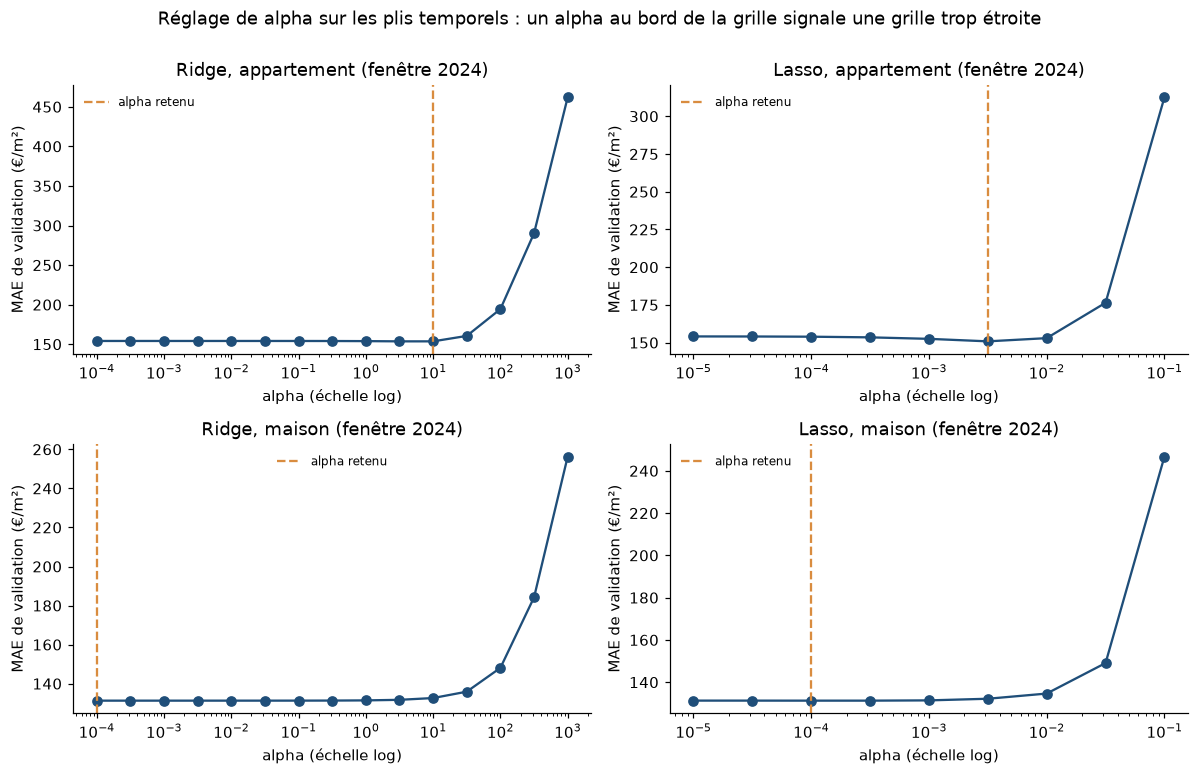

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (nom, etiquette) in enumerate([(RIDGE, "Ridge"), (LASSO, "Lasso")]):
    for i, tb in enumerate(["appartement", "maison"]):
        m = ajustes[(nom, 2024, tb)][0]
        cv = pd.DataFrame(m.cv_results_).sort_values("param_regressor__modele__alpha")
        a = cv["param_regressor__modele__alpha"].astype(float)
        ax = axes[i, j]
        ax.semilogx(a, -cv["mean_test_score"], marker="o", color="#1f4e79")
        ax.axvline(m.best_params_["regressor__modele__alpha"], color="#d98c3f", ls="--", label="alpha retenu")
        ax.set_title(f"{etiquette}, {tb} (fenêtre 2024)")
        ax.set_xlabel("alpha (échelle log)")
        ax.set_ylabel("MAE de validation (€/m²)")
        ax.legend(frameon=False, fontsize=8)
fig.suptitle("Réglage de alpha sur les plis temporels : un alpha au bord de la grille signale une grille trop étroite", y=1.0)
fig.tight_layout()
plt.show()

### 4.3 Variante : modèle complet + équipements (piste H3a), et régularisation sur le prix N-1 seul
- **Équipements :** Théophyle signale un gain faible des équipements pour les maisons ; on les ajoute au modèle complet pour voir s'ils tiennent quand le reste est là.
- **Régularisation sur le prix N-1 seul :** H3a observe que le gain du Lasso ne vient pas de l'attractivité mais de la régularisation du prix N-1, et propose de le confirmer avec un Lasso sur le prix N-1 seul. C'est fait ici, avec Ridge et Lasso.

In [11]:
RIDGE_EQ = lancer("Ridge – complet + équipements", Ridge(), AVEC_EQUIPEMENTS, log=True, grille=GRILLE_RIDGE)
LASSO_EQ = lancer("Lasso – complet + équipements", Lasso(max_iter=50_000), AVEC_EQUIPEMENTS, log=True, grille=GRILLE_LASSO)
ELASTIC_EQ = lancer("Elastic Net – complet + équipements", ElasticNet(max_iter=50_000), AVEC_EQUIPEMENTS, log=True, grille=GRILLE_EN)
RIDGE_REF = lancer("Ridge – prix N-1 seul", Ridge(), REFERENCE_VARS, log=True, grille=GRILLE_RIDGE)
LASSO_REF = lancer("Lasso – prix N-1 seul", Lasso(max_iter=50_000), REFERENCE_VARS, log=True, grille=GRILLE_LASSO)

H3 – Ridge – complet + équipements (18 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       171.5             166.3                   -3.1                            48.4
      maison         2023       154.6             111.7                  -38.4                            32.6
 appartement         2024       202.8             148.0                  -37.0                            30.1
      maison         2024       192.6             129.2                  -49.1                            21.4
H3 – Lasso – complet + équipements (18 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       167.8             166.3                   -0.9                            47.6
      maison         2023       156.9             111.7                  -40.4                            32.2
 appartement

### 4.4 Étape 1.3 : modèle hiérarchique (P4)
Une ordonnée à l'origine propre à chaque sous-bassin (`gabarit_hierarchique.py`), en log, sur le modèle complet. L'ICC mesure la part de la variance qui tient au sous-bassin : proche de 0, l'effet propre du territoire n'apporte rien au-delà du prix N-1 et le modèle se comporte comme une régression simple. Des avertissements de convergence sont attendus dans ce cas (solution sur le bord).

In [12]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # convergence du modèle mixte : relevée par m.modele_.converge_ (ci-dessous)
    HIERARCHIQUE = lancer("Hiérarchique – modèle complet", ModeleHierarchique(), MODELE_COMPLET, log=True)
icc = pd.DataFrame({(a, t): {"ICC": ajustes[(HIERARCHIQUE, a, t)][0].modele_.icc_,
                             "convergence": ajustes[(HIERARCHIQUE, a, t)][0].modele_.converge_}
                    for a in commun.ANNEES_JUGEES for t in ["appartement", "maison"]}).T
icc.index.names = ["année jugée", "type de bien"]
icc.round(4)

H3 – Hiérarchique – modèle complet (12 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       171.8             166.3                   -3.3                            48.5
      maison         2023       156.8             111.7                  -40.3                            32.6
 appartement         2024       205.3             148.0                  -38.7                            29.3
      maison         2024       197.0             129.2                  -52.5                            21.5


ICC convergence
année jugée type de bien                      
2023        appartement        0.0        True
            maison         0.00084       False
2024        appartement   0.000799        True
            maison             0.0        True

### 4.5 Étape 1.4 : arbre, forêt et gradient boosting (P3)
- **Gradient boosting (gabarit commun)** : il apprend l'évolution du prix (log(prix / prix N-1)) et rend une prévision en €/m². Grille commune du gabarit.
- **Arbre et forêt** : prévoient directement le niveau du prix, comme le demande la feuille de route. Ils rendent la moyenne des prix de chaque feuille et perdent la précision du prix N-1 de chaque sous-bassin (raison pour laquelle le gabarit apprend l'évolution) : ils servent de contraste. Pas de log, pas d'imputation nécessaire (table masquée).

In [13]:
BOOSTING = lancer("Gradient boosting – modèle complet", BoostingEvolution(), MODELE_COMPLET)
ARBRE = lancer("Arbre – modèle complet", DecisionTreeRegressor(random_state=commun.GRAINE), MODELE_COMPLET,
               grille={"max_depth": [3, 5, 8], "min_samples_leaf": [20, 50]})
FORET = lancer("Forêt – modèle complet", RandomForestRegressor(n_estimators=200, random_state=commun.GRAINE, n_jobs=-1),
               MODELE_COMPLET, grille={"max_depth": [5, 10], "min_samples_leaf": [20, 50]})

H3 – Gradient boosting – modèle complet (12 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       178.6             166.3                   -7.4                            48.4
      maison         2023       166.9             111.7                  -49.4                            32.5
 appartement         2024       213.5             148.0                  -44.3                            27.7
      maison         2024       204.8             129.2                  -58.5                            21.3
H3 – Arbre – modèle complet (12 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2023       203.3             166.3                  -22.3                            45.6
      maison         2023       199.5             111.7                  -78.6                            30.2
 appartement  

### 4.6 Emploi (H3c) pour les maisons : à ajouter
Gabrielle retient le bloc emploi (`evol_emploi_n2_n1`, `emploi_par_logement`) pour les maisons avec le gradient boosting. Ces deux colonnes sont dans `fe_cible_emploi_sbv.parquet`, pas dans la table de modélisation : le boosting avec emploi se lance ici une fois ce fichier joint (année et sous-bassin). Pas fait dans cette version.

## 5. Mesures et tests
Trois tableaux, du plus simple au plus exigeant :
1. **`res` : les erreurs.** MAE du modèle et de la naïve en €/m², gain sur la naïve en %, part des sous-bassins où le modèle gagne. C'est une description : un modèle peut avoir une MAE plus basse par hasard.
2. **`tst` : les tests contre la naïve.** Ils disent si l'écart avec la naïve est plus grand que le hasard.
   - **Écart de MAE avec la naïve** : erreur du modèle moins erreur de la naïve, en €/m² (négatif : le modèle fait mieux).
   - **IC 95 %** (bootstrap par bassin de vie) : la fourchette dans laquelle se trouve cet écart, en tenant compte du hasard. Si toute la fourchette est sous 0, le modèle fait vraiment mieux ; si elle contient 0, on ne peut pas conclure ; si elle est toute au-dessus de 0, il fait vraiment moins bien.
   - **p-value de Wilcoxon** : le modèle fait-il mieux (ou moins bien) dans la plupart des sous-bassins ? Avec plusieurs centaines de sous-bassins, elle est presque toujours très petite : on la lit avec la taille d'effet.
   - **Rang-bisériale** (taille d'effet) : de −1 (le modèle fait mieux partout) à +1 (il fait moins bien partout) ; autour de 0, pas de différence nette.
3. **`decision` : la règle de décision.** Une année est réussie si l'IC est entièrement sous 0, la rang-bisériale négative et le gain d'au moins 3 %. Un modèle est retenu s'il réussit la majorité des années jugées (ici, les deux).

In [14]:
res = pd.DataFrame(resultats)
res.round(2)

,modèle,type de bien,année jugée,MAE (€/m²),MAE en % du prix,MAE naïve (€/m²),gain sur la naïve (%),bassins où le modèle gagne (%)
0,H3 – Régression linéaire – prix N-1 seul,appartement,2023,185.46,7.07,166.33,-11.51,45.64
1,H3 – Régression linéaire – prix N-1 seul,maison,2023,170.00,7.76,111.71,-52.18,30.96
2,H3 – Régression linéaire – prix N-1 seul,appartement,2024,221.51,8.50,148.00,-49.67,26.97
3,H3 – Régression linéaire – prix N-1 seul,maison,2024,214.92,9.64,129.19,-66.36,18.24
4,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2023,195.10,7.18,166.33,-17.30,45.30
5,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2023,164.36,7.63,111.71,-47.13,31.35
6,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2024,232.38,8.64,148.00,-57.02,26.49
7,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2024,210.07,9.54,129.19,-62.61,18.13
8,H3 – Ridge – modèle complet,appartement,2023,170.90,6.58,166.33,-2.75,48.78
9,H3 – Ridge – modèle complet,maison,2023,156.75,7.10,111.71,-40.32,32.53


In [15]:
tst = pd.DataFrame(tests)
tst.round(3)

,modèle,type de bien,année jugée,écart de MAE avec la naïve (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale,bassins de vie
0,H3 – Régression linéaire – prix N-1 seul,appartement,2023,19.140,-2.677,45.770,0.004,0.114,726
1,H3 – Régression linéaire – prix N-1 seul,maison,2023,58.291,50.608,65.476,0.000,0.471,1606
2,H3 – Régression linéaire – prix N-1 seul,appartement,2024,73.509,59.615,87.685,0.000,0.606,692
3,H3 – Régression linéaire – prix N-1 seul,maison,2024,85.732,80.270,91.580,0.000,0.778,1605
4,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2023,28.775,-0.377,68.084,0.000,0.139,726
5,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2023,52.652,45.381,59.378,0.000,0.447,1606
6,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2024,84.384,65.569,106.610,0.000,0.621,692
7,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2024,80.881,75.926,85.991,0.000,0.774,1605
8,H3 – Ridge – modèle complet,appartement,2023,4.574,-8.071,17.619,0.259,0.044,726
9,H3 – Ridge – modèle complet,maison,2023,45.046,38.149,51.432,0.000,0.413,1606


### 5.1 Règle de décision contre la naïve

In [16]:
SEUIL_GAIN = 3      # % de gain sur la MAE de la comparaison, fixé avant les résultats


def regle_decision(res, tst, comparaison="naïve"):
    """Années réussies et décision, par modèle et type de bien."""
    cles = ["modèle", "type de bien", "année jugée"]
    regle = res[cles + [f"gain sur la {comparaison} (%)"]].merge(
        tst[cles + ["IC 95 % haut (€/m²)", "rang-bisériale"]], on=cles)
    regle["année réussie"] = ((regle["IC 95 % haut (€/m²)"] < 0) & (regle["rang-bisériale"] < 0)
                              & (regle[f"gain sur la {comparaison} (%)"] >= SEUIL_GAIN))
    decision = regle.groupby(["modèle", "type de bien"], sort=False)["année réussie"].agg(["sum", "count"])
    decision["retenu"] = decision["sum"] > decision["count"] / 2
    return decision.rename(columns={"sum": "années réussies", "count": "années jugées"})


regle_decision(res, tst)

années réussies  \
modèle                                             type de bien                    
H3 – Régression linéaire – prix N-1 seul           appartement                 0   
                                                   maison                      0   
H3 – Régression linéaire – prix N-1 seul, commu... appartement                 0   
                                                   maison                      0   
H3 – Ridge – modèle complet                        appartement                 0   
                                                   maison                      0   
H3 – Lasso – modèle complet                        appartement                 0   
                                                   maison                      0   
H3 – Elastic Net – modèle complet                  appartement                 0   
                                                   maison                      0   
H3 – Ridge – complet + équipements                 appartement                 0   
                                                   maison                      0   
H3 – Lasso – complet + équipements                 appartement                 0   
                                                   maison                      0   
H3 – Elastic Net – complet + équipements           appartement                 0   
                                                   maison                      0   
H3 – Ridge – prix N-1 seul                         appartement                 0   
                                                   maison                      0   
H3 – Lasso – prix N-1 seul                         appartement                 0   
                                                   maison                      0   
H3 – Hiérarchique – modèle complet                 appartement                 0   
                                                   maison                      0   
H3 – Gradient boosting – modèle complet            appartement                 0   
                                                   maison                      0   
H3 – Arbre – modèle complet                        appartement                 0   
                                                   maison                      0   
H3 – Forêt – modèle complet                        appartement                 0   
                                                   maison                      0   

                                                                 années jugées  \
modèle                                             type de bien                  
H3 – Régression linéaire – prix N-1 seul           appartement               2   
                                                   maison                    2   
H3 – Régression linéaire – prix N-1 seul, commu... appartement               2   
                                                   maison                    2   
H3 – Ridge – modèle complet                        appartement               2   
                                                   maison                    2   
H3 – Lasso – modèle complet                        appartement               2   
                                                   maison                    2   
H3 – Elastic Net – modèle complet                  appartement               2   
                                                   maison                    2   
H3 – Ridge – complet + équipements                 appartement               2   
                                                   maison                    2   
H3 – Lasso – complet + équipements                 appartement               2   
                                                   maison                    2   
H3 – Elastic Net – complet + équipements           appartement               2   
                                                   maison                    2   
H3 – Ridge – prix N-1 seul                         appartement      

In [17]:
def forest(df, col, titre):
    """Écart de MAE de chaque modèle avec une référence, avec l'IC 95 % : bleu = mieux, gris = pas de différence nette, orange = moins bien."""
    d = df.copy()
    d["m"] = d["modèle"].str.replace(f"{HYPOTHESE} – ", "", regex=False)
    modeles = list(dict.fromkeys(d["m"]))
    annees, types = sorted(d["année jugée"].unique()), sorted(d["type de bien"].unique())
    fig, axes = plt.subplots(len(types), len(annees), figsize=(12.5, 0.34 * len(modeles) * len(types) + 1.8), sharey=True, squeeze=False)
    for i, tb in enumerate(types):
        for j, a in enumerate(annees):
            ax = axes[i, j]
            s = d[(d["type de bien"] == tb) & (d["année jugée"] == a)].set_index("m").reindex(modeles)
            for y, (m, r) in enumerate(s.iterrows()):
                bas, haut = r["IC 95 % bas (€/m²)"], r["IC 95 % haut (€/m²)"]
                c = BLEU if haut < 0 else ("#d98c3f" if bas > 0 else GRIS)
                ax.hlines(y, bas, haut, color=c, lw=2)
                ax.plot(r[col], y, "o", color=c)
            ax.axvline(0, color="black", lw=1)
            ax.set_yticks(range(len(modeles)), modeles, fontsize=8)
            ax.invert_yaxis()
            ax.set_title(f"{tb}, jugée {a}", fontsize=10)
            if i == len(types) - 1:
                ax.set_xlabel("écart de MAE (€/m²) ; à gauche de 0 : mieux")
    fig.suptitle(titre, y=1.0)
    fig.tight_layout()
    plt.show()

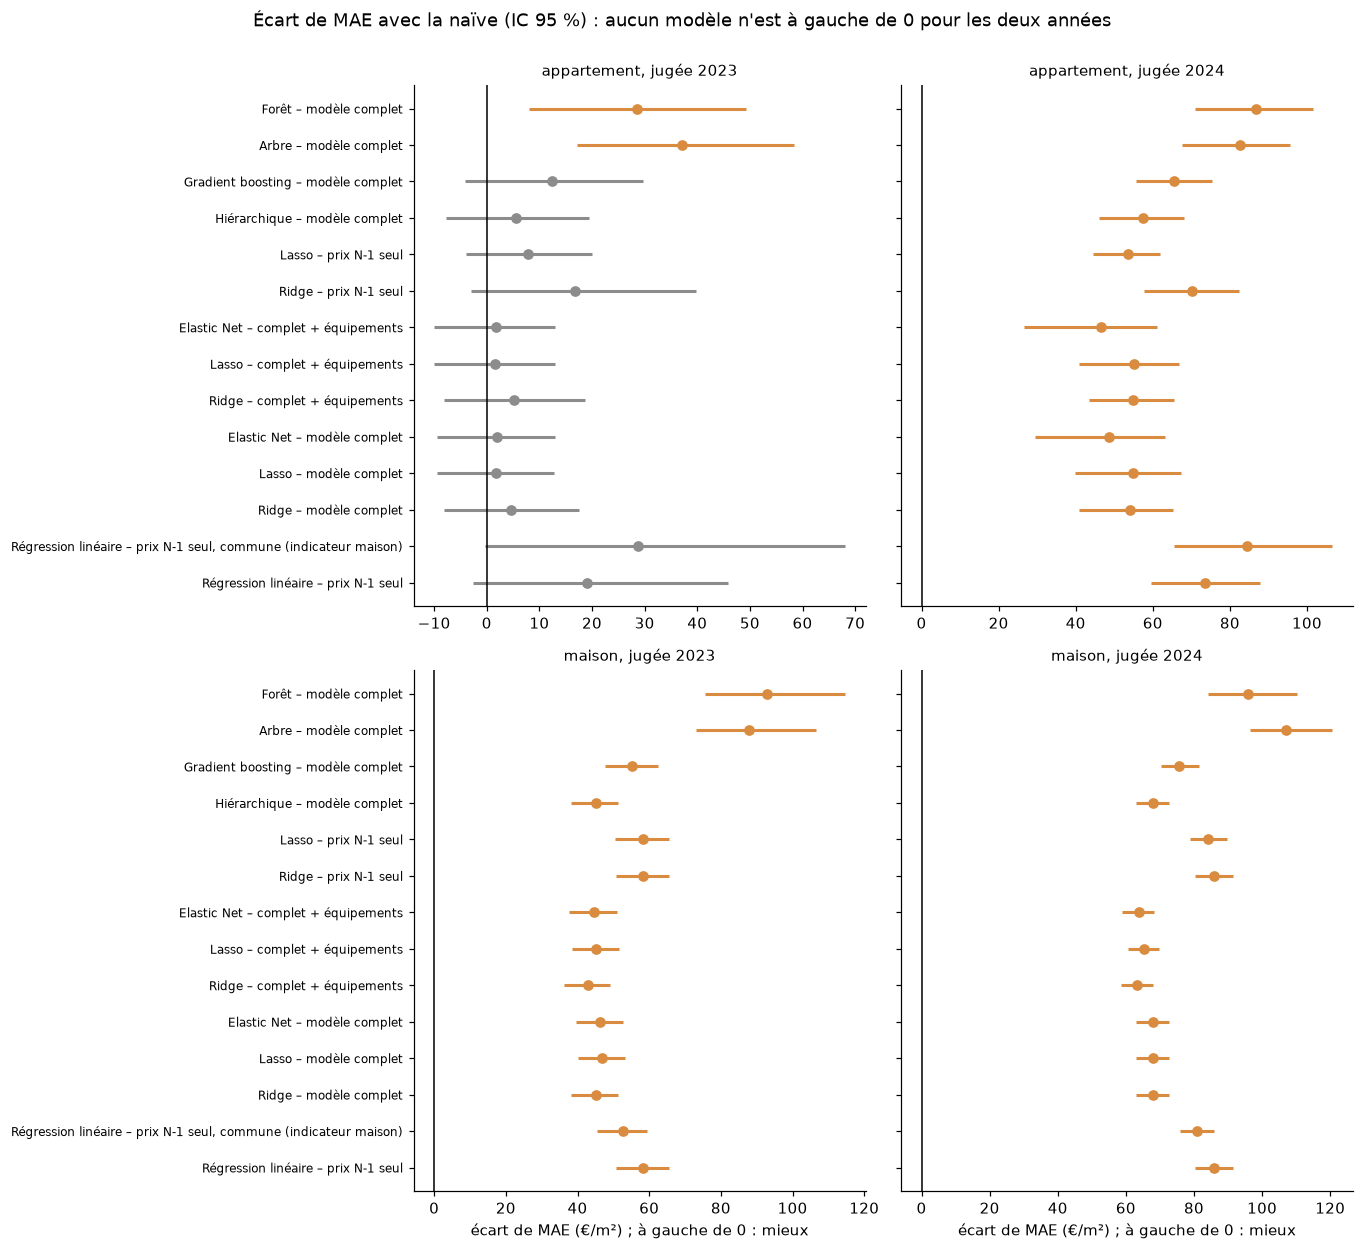

In [18]:
forest(tst, "écart de MAE avec la naïve (€/m²)",
       "Écart de MAE avec la naïve (IC 95 %) : aucun modèle n'est à gauche de 0 pour les deux années")

**Comment lire le tableau des tests.** Prenons « Ridge – modèle complet », appartements, 2023 : l'écart de MAE avec la naïve est positif (le modèle fait un peu moins bien) et l'IC 95 % contient 0 : on ne peut pas conclure à une différence. La même ligne en 2024 a un IC entièrement au-dessus de 0 : le modèle fait vraiment moins bien que la naïve.

**Résultats contre la naïve :** aucun modèle n'est retenu, pour les deux types de bien (0 année réussie sur 2 partout, y compris le hiérarchique, le gradient boosting, l'arbre et la forêt). Le gain sur la naïve est négatif dans tous les cas : de −1 % (appartements 2023, régularisées) à −83 % (maisons 2023, forêt). Le modèle « prix N-1 seul » perd aussi (−12 % à −66 %).

### 5.2 Le bloc apporte-t-il quelque chose au prix N-1 seul ?
La question propre à l'hypothèse : les variables du bloc améliorent-elles la prévision **par rapport au modèle « prix N-1 seul »** ?

On applique exactement les mêmes mesures et la même règle de décision, en remplaçant la naïve par la prévision du modèle « prix N-1 seul ». Les fonctions `evaluer` et `tester` lisent la prévision de comparaison dans la colonne `prix_n1` : on leur donne une copie de l'année jugée où cette colonne contient la prévision de la référence.

Lecture : un gain positif et un intervalle du bootstrap entièrement sous 0 veulent dire que le modèle fait vraiment mieux que la référence.

In [19]:
resultats_ref, tests_ref = [], []
modeles_compares = [n for n in dict.fromkeys(k[0] for k in previsions) if n != REFERENCE]

for nom in modeles_compares:
    for annee, (app, ev) in FENETRES.items():
        ev_ref = ev.copy()
        ev_ref["prix_n1"] = previsions[(REFERENCE, annee)]     # la comparaison se fait avec la référence
        evaluer(nom, ev_ref, previsions[(nom, annee)], resultats_ref)
        tester(nom, ev_ref, previsions[(nom, annee)], tests_ref)

# Mêmes tableaux que contre la naïve, avec « référence » à la place de « naïve »
res_ref = pd.DataFrame(resultats_ref).rename(columns=lambda c: c.replace("naïve", "référence"))
tst_ref = pd.DataFrame(tests_ref).rename(columns=lambda c: c.replace("naïve", "référence"))
display(res_ref[["modèle", "type de bien", "année jugée", "MAE (€/m²)", "MAE référence (€/m²)",
                 "gain sur la référence (%)", "bassins où le modèle gagne (%)"]].round(2))
display(tst_ref[["modèle", "type de bien", "année jugée", "écart de MAE avec la référence (€/m²)",
                 "IC 95 % bas (€/m²)", "IC 95 % haut (€/m²)", "p-value Wilcoxon", "rang-bisériale"]].round(3))

,modèle,type de bien,année jugée,MAE (€/m²),MAE référence (€/m²),gain sur la référence (%),bassins où le modèle gagne (%)
0,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2023,195.10,185.46,-5.20,45.76
1,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2023,164.36,170.00,3.32,61.52
2,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2024,232.38,221.51,-4.91,38.03
3,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2024,210.07,214.92,2.26,61.15
4,H3 – Ridge – modèle complet,appartement,2023,170.90,185.46,7.85,58.77
5,H3 – Ridge – modèle complet,maison,2023,156.75,170.00,7.79,68.26
6,H3 – Ridge – modèle complet,appartement,2024,202.03,221.51,8.80,61.24
7,H3 – Ridge – modèle complet,maison,2024,197.03,214.92,8.33,69.76
8,H3 – Lasso – modèle complet,appartement,2023,168.13,185.46,9.35,60.05
9,H3 – Lasso – modèle complet,maison,2023,158.57,170.00,6.72,67.42


,modèle,type de bien,année jugée,écart de MAE avec la référence (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale
0,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2023,9.636,1.666,22.565,0.000,0.208
1,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2023,-5.639,-6.770,-4.545,0.000,-0.425
2,"H3 – Régression linéaire – prix N-1 seul, comm...",appartement,2024,10.875,5.460,19.329,0.000,0.421
3,"H3 – Régression linéaire – prix N-1 seul, comm...",maison,2024,-4.851,-5.753,-4.115,0.000,-0.465
4,H3 – Ridge – modèle complet,appartement,2023,-14.565,-32.703,-2.605,0.000,-0.232
5,H3 – Ridge – modèle complet,maison,2023,-13.245,-16.509,-10.259,0.000,-0.458
6,H3 – Ridge – modèle complet,appartement,2024,-19.482,-40.643,-4.705,0.000,-0.268
7,H3 – Ridge – modèle complet,maison,2024,-17.894,-22.994,-13.683,0.000,-0.450
8,H3 – Lasso – modèle complet,appartement,2023,-17.335,-39.450,-3.841,0.000,-0.294
9,H3 – Lasso – modèle complet,maison,2023,-11.426,-14.246,-8.709,0.000,-0.441


#### Règle de décision contre la référence
Même règle que contre la naïve, avec le modèle « prix N-1 seul » à la place de la naïve.

In [20]:
regle_decision(res_ref, tst_ref, comparaison="référence")

années réussies  \
modèle                                             type de bien                    
H3 – Régression linéaire – prix N-1 seul, commu... appartement                 0   
                                                   maison                      1   
H3 – Ridge – modèle complet                        appartement                 2   
                                                   maison                      2   
H3 – Lasso – modèle complet                        appartement                 2   
                                                   maison                      2   
H3 – Elastic Net – modèle complet                  appartement                 2   
                                                   maison                      2   
H3 – Ridge – complet + équipements                 appartement                 2   
                                                   maison                      2   
H3 – Lasso – complet + équipements                 appartement                 2   
                                                   maison                      2   
H3 – Elastic Net – complet + équipements           appartement                 2   
                                                   maison                      2   
H3 – Ridge – prix N-1 seul                         appartement                 0   
                                                   maison                      0   
H3 – Lasso – prix N-1 seul                         appartement                 1   
                                                   maison                      0   
H3 – Hiérarchique – modèle complet                 appartement                 2   
                                                   maison                      2   
H3 – Gradient boosting – modèle complet            appartement                 0   
                                                   maison                      1   
H3 – Arbre – modèle complet                        appartement                 0   
                                                   maison                      0   
H3 – Forêt – modèle complet                        appartement                 0   
                                                   maison                      0   

                                                                 années jugées  \
modèle                                             type de bien                  
H3 – Régression linéaire – prix N-1 seul, commu... appartement               2   
                                                   maison                    2   
H3 – Ridge – modèle complet                        appartement               2   
                                                   maison                    2   
H3 – Lasso – modèle complet                        appartement               2   
                                                   maison                    2   
H3 – Elastic Net – modèle complet                  appartement               2   
                                                   maison                    2   
H3 – Ridge – complet + équipements                 appartement               2   
                                                   maison                    2   
H3 – Lasso – complet + équipements                 appartement               2   
                                                   maison                    2   
H3 – Elastic Net – complet + équipements           appartement               2   
                                                   maison                    2   
H3 – Ridge – prix N-1 seul                         appartement               2   
                                                   maison                    2   
H3 – Lasso – prix N-1 seul                         appartement               2   
                                                   maison                    2   
H3 – Hiérarchique – modèle complet                 appartement          

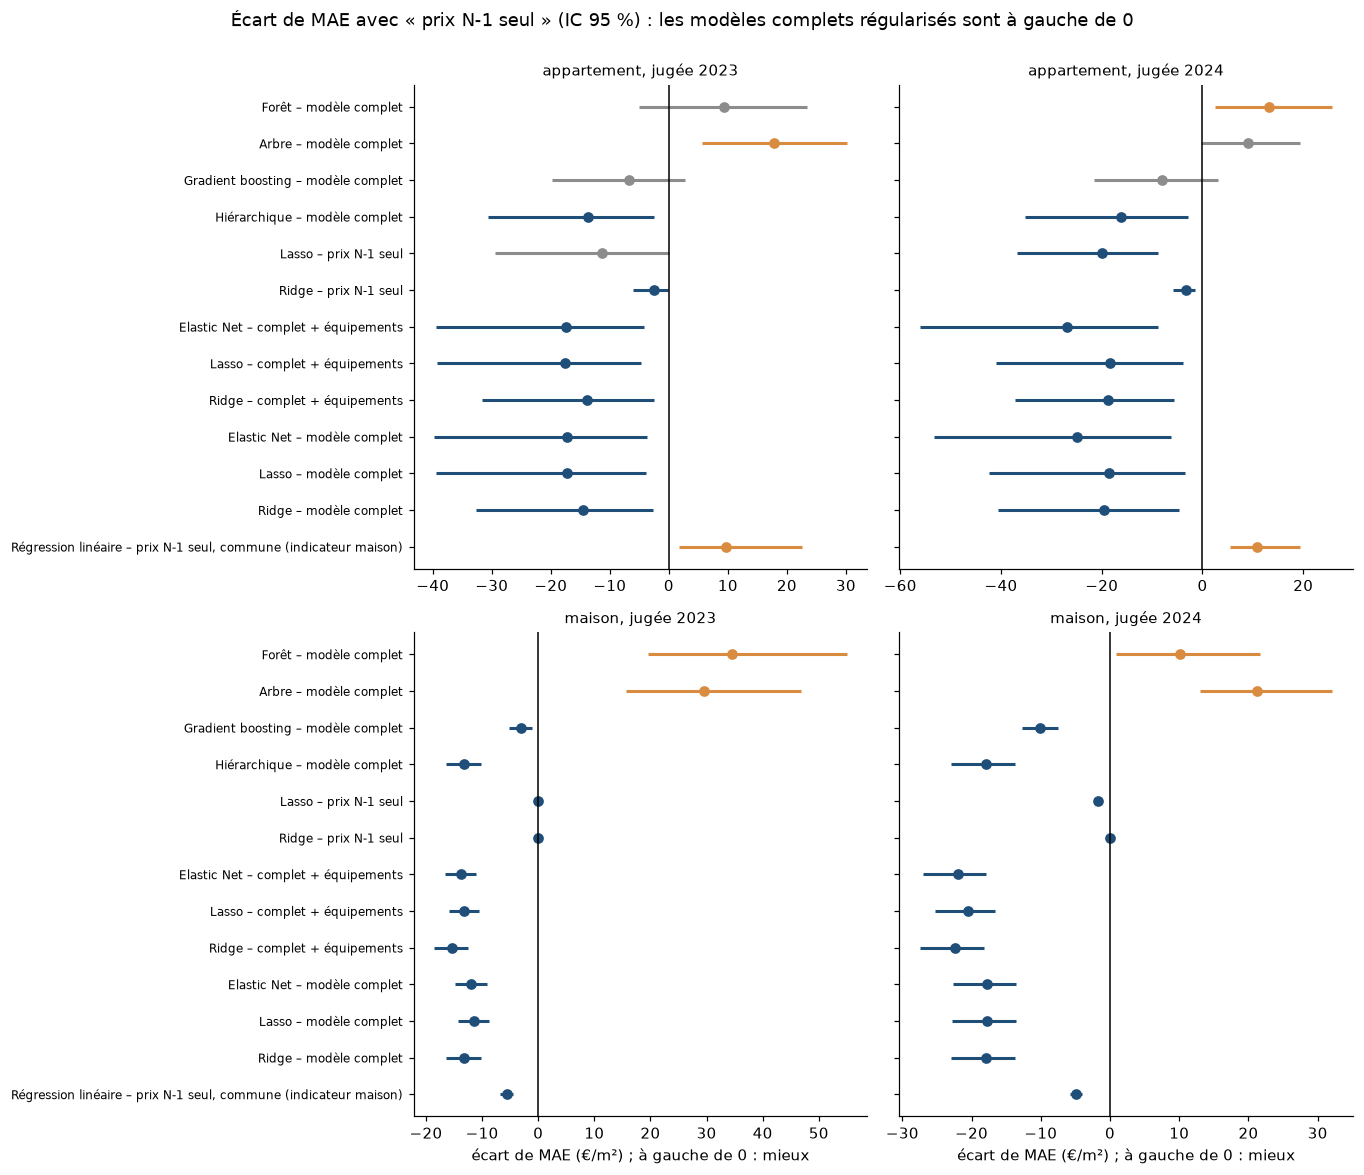

In [21]:
forest(tst_ref, "écart de MAE avec la référence (€/m²)",
       "Écart de MAE avec « prix N-1 seul » (IC 95 %) : les modèles complets régularisés sont à gauche de 0")

**Comment lire le tableau des tests contre la référence.** Prenons « Lasso – modèle complet », maisons, 2024 : le gain sur « prix N-1 seul » est de 8,3 % et l'IC 95 % est entièrement sous 0 (haut à −14 €/m²) : le modèle fait vraiment mieux que la référence.

**Résultats contre le modèle « prix N-1 seul » :**
- **Modèle complet (parc + vacance + densité) :** Ridge, Lasso, Elastic Net et hiérarchique sont retenus pour les deux types de bien (2 années sur 2). Gains de 7 à 11 %.
- **Piste H3a, équipements en plus :** les trois régularisées restent retenues ; pour les maisons le gain monte un peu (8 à 10 % contre 7 à 8 %), pour les appartements il ne change pas. Écart de quelques €/m² : à ne pas sur-lire.
- **Régularisation seule (prix N-1 seul) :** Ridge apporte 1 à 2 % ; Lasso apporte 6 % (2023) et 9 % (2024) aux appartements, et rien aux maisons (0 à 1 %). Pour les appartements, une grande part du gain du modèle complet vient donc de la régularisation du prix N-1, comme le suggérait H3a ; pour les maisons, il vient bien des variables du bloc.
- **Gradient boosting :** gain de 2 à 5 % ; retenu pour les maisons en 2024 seulement (2023 : 1,8 %, sous le seuil), pas pour les appartements. **Arbre et forêt :** moins bons que la référence (−4 à −20 %), comme attendu quand on prévoit le niveau plutôt que l'évolution.
- **Modèle commun :** moins bon que le séparé pour les appartements (−5 %), un peu meilleur pour les maisons (+2 à +3 %).
- **Réserve :** ces gains sont mesurés contre une référence qui perd elle-même contre la naïve. Ils ne disent pas que le modèle est utilisable.

## 6. Interprétation

### 6.1 Contexte : le marché s'est-il retourné ?
Les modèles apprennent sur les années de hausse 2020-2022, puis sont jugés sur 2023 et 2024. Pour lire leurs résultats, on mesure l'évolution du prix d'une année sur l'autre (prix / prix N-1 − 1), en moyenne et en médiane, par année et par type de bien, jusqu'à 2024. L'année 2025, réservée au test final, n'est pas regardée.

In [22]:
jusqua_2024 = table[table["annee"] <= commun.ANNEE_VALIDATION]
evolution = (jusqua_2024[CIBLE] / jusqua_2024["prix_n1"] - 1) * 100
retournement = (evolution.groupby([jusqua_2024["annee"], jusqua_2024.index.get_level_values("type_bien")])
                .agg(["mean", "median"]).round(1)
                .rename(columns={"mean": "évolution moyenne (%)", "median": "évolution médiane (%)"}))
retournement.unstack()

évolution moyenne (%)        évolution médiane (%)       
type_bien           appartement maison           appartement maison
annee                                                              
2017                        2.2    1.8                   2.1    2.0
2018                        1.4    2.1                   1.5    2.1
2019                        3.2    2.3                   3.0    2.3
2020                        5.2    4.7                   5.1    4.7
2021                        8.0    7.9                   7.5    7.7
2022                        8.8    9.6                   8.2    9.1
2023                        2.9    1.3                   2.9    0.8
2024                       -0.8   -2.4                  -1.5   -2.9

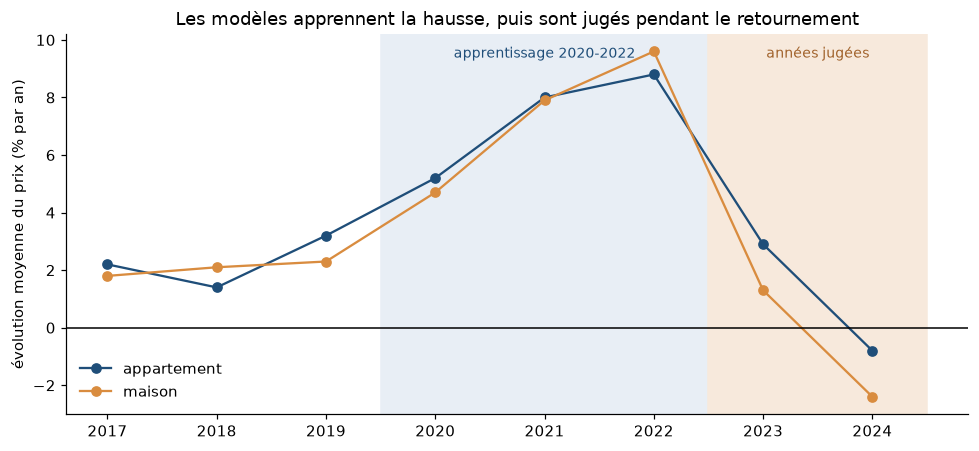

In [23]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLEU, GRIS = "#1f4e79", "#8c8c8c"
fig, ax = plt.subplots(figsize=(9, 4.2))
mean = retournement["évolution moyenne (%)"].unstack()
ax.axvspan(2019.5, 2022.5, color="#e8eef5", zorder=0)
ax.axvspan(2022.5, 2024.5, color="#f7e9dc", zorder=0)
ax.plot(mean.index, mean["appartement"], marker="o", color=BLEU, label="appartement")
ax.plot(mean.index, mean["maison"], marker="o", color="#d98c3f", label="maison")
ax.axhline(0, color="black", lw=1)
ax.text(2021, ax.get_ylim()[1] * 0.92, "apprentissage 2020-2022", ha="center", fontsize=9, color=BLEU)
ax.text(2023.5, ax.get_ylim()[1] * 0.92, "années jugées", ha="center", fontsize=9, color="#a0612a")
ax.set_ylabel("évolution moyenne du prix (% par an)")
ax.set_title("Les modèles apprennent la hausse, puis sont jugés pendant le retournement")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
plt.show()

### 6.2 Importance des variables
Importance par permutation, sur l'année jugée : on mélange au hasard les valeurs d'une variable entre les sous-bassins, 10 fois, et on mesure de combien l'erreur du modèle change (moyenne et écart-type). Une hausse : la variable était utile ; 0 : le modèle ne s'en sert pas ; une baisse : sur cette année, la variable dessert le modèle. Une variable compte si sa valeur dépasse nettement deux écarts-types. Choisir le modèle, l'année jugée et le type de bien.

In [24]:
choix = (LASSO, 2024, "maison")        # modèle, année jugée, type de bien étudiés (à adapter)
m, X_ev, y_ev = ajustes[choix]
imp = permutation_importance(m, X_ev, y_ev, scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=commun.GRAINE)
pd.DataFrame({"hausse de la MAE (€/m²)": imp.importances_mean,
              "écart-type (€/m²)": imp.importances_std},
             index=X_ev.columns).sort_values("hausse de la MAE (€/m²)", ascending=False).round(1)

,hausse de la MAE (€/m²),écart-type (€/m²)
prix_n1,935.6,16.5
part_rsec,6.5,0.6
log_nb_logements,1.7,0.1
part_sans_voiture,-0.4,0.6
anciennete_moyenne,-2.0,0.2
part_avant1946,-2.1,0.1
taux_vacance_complete,-2.5,0.3
part_moins40m2,-3.3,0.3
part_apparts,-3.8,0.2
part_2006_2019,-4.2,0.4


### 6.3 Analyse des erreurs selon le contrôle qualité
L'erreur est-elle plus grande là où les données sont estimées ou complétées ? Pour chaque variable de contrôle qualité : groupe « part nulle », puis quartiles parmi les parts non nulles. Par groupe : erreur moyenne en €/m² et en % du prix (l'erreur en €/m² grandit avec le niveau des prix), et erreur moyenne signée (positive : le modèle surestime). Rho de Spearman entre la variable et l'erreur, en €/m² et en %. Même modèle qu'en 6.2.

In [25]:
CONTROLE = ["part_indicateurs_estimes", "part_logements_taux_impute", "part_menages_couverts"]

m, X_ev, y_ev = ajustes[choix]
erreur = pd.Series(m.predict(X_ev), index=X_ev.index) - y_ev       # signée : positive = prix surestimé
erreur_pct = erreur.abs() / y_ev * 100                             # erreur absolue en % du prix réel
controle = table.loc[X_ev.index, CONTROLE]

for v in CONTROLE:
    x = controle[v]
    groupe = pd.Series("part nulle", index=x.index)
    non_nul = x > 0
    if non_nul.sum() >= 4:
        groupe[non_nul] = pd.qcut(x[non_nul], 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop").astype(str)
    tableau = pd.DataFrame({"MAE (€/m²)": erreur.abs(), "erreur en % du prix": erreur_pct,
                            "erreur signée (€/m²)": erreur}).groupby(groupe).mean()
    tableau["lignes"] = groupe.value_counts()
    rho, p = stats.spearmanr(x, erreur.abs())
    rho_pct, _ = stats.spearmanr(x, erreur_pct)
    print(f"\n{v} : rho avec l'erreur en €/m² = {rho:.2f} (p = {p:.3f}) | rho avec l'erreur en % = {rho_pct:.2f}")
    print(tableau.round(1).to_string())


part_indicateurs_estimes : rho avec l'erreur en €/m² = -0.17 (p = 0.000) | rho avec l'erreur en % = -0.04
            MAE (€/m²)  erreur en % du prix  erreur signée (€/m²)  lignes
Q1               254.4                  9.0                 238.2     439
Q2               173.5                  8.6                 146.7     439
Q3               169.6                  8.5                 145.7     438
Q4               182.9                  9.0                 155.3     439
part nulle       364.1                  9.3                 337.4      21

part_logements_taux_impute : rho avec l'erreur en €/m² = -0.37 (p = 0.000) | rho avec l'erreur en % = -0.14
            MAE (€/m²)  erreur en % du prix  erreur signée (€/m²)  lignes
Q1               213.4                  8.7                 203.5     346
Q2               162.1                  8.0                 131.5     345
Q3               145.4                  8.2                 117.4     345
Q4               133.5                  8.7 

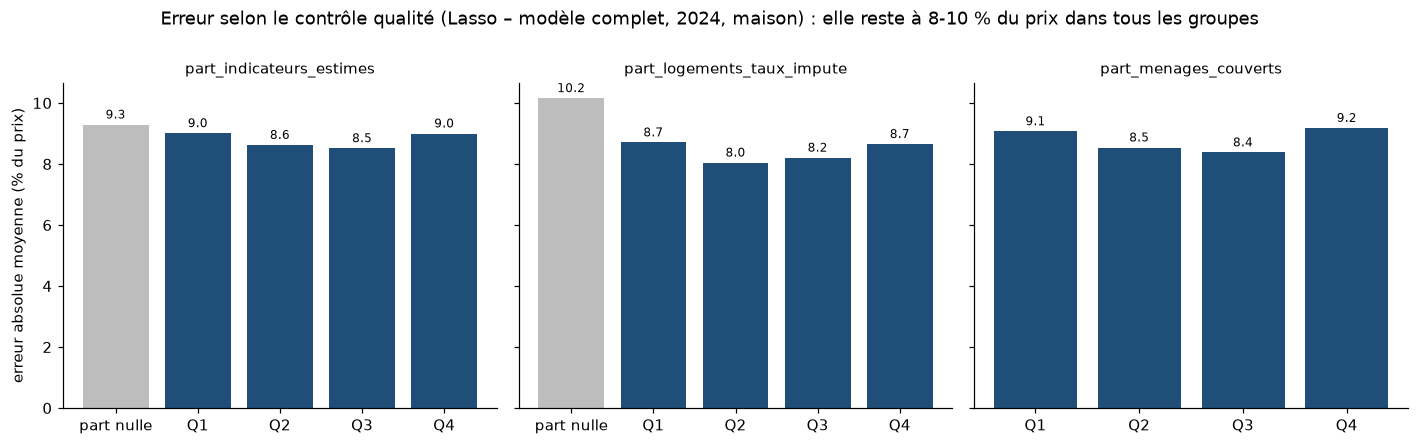

In [26]:
ordre_groupes = ["part nulle", "Q1", "Q2", "Q3", "Q4"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, v in zip(axes, CONTROLE):
    x = controle[v]
    groupe = pd.Series("part nulle", index=x.index)
    non_nul = x > 0
    if non_nul.sum() >= 4:
        groupe[non_nul] = pd.qcut(x[non_nul], 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop").astype(str)
    moy = erreur_pct.groupby(groupe).mean().reindex([g for g in ordre_groupes if g in set(groupe)])
    b = ax.bar(moy.index, moy.values, color=["#bdbdbd" if g == "part nulle" else BLEU for g in moy.index])
    ax.bar_label(b, fmt="%.1f", fontsize=8, padding=2)
    ax.set_title(v, fontsize=10)
axes[0].set_ylabel("erreur absolue moyenne (% du prix)")
fig.suptitle(f"Erreur selon le contrôle qualité ({choix[0].split(' – ', 1)[1]}, {choix[1]}, {choix[2]}) : elle reste à 8-10 % du prix dans tous les groupes", y=1.0)
fig.tight_layout()
plt.show()

### 6.4 Quelles variables survivent au Lasso ?
Coefficients du Lasso « modèle complet » (variables transformées et mises à l'échelle, cible en log), année jugée 2024, par type de bien. Un coefficient nul : la variable est écartée à l'alpha retenu.

In [27]:
def coefficients(nom, annee, type_bien):
    m = ajustes[(nom, annee, type_bien)][0]
    est = m.best_estimator_ if hasattr(m, "best_estimator_") else m
    return pd.Series(est.regressor_.named_steps["modele"].coef_, index=MODELE_COMPLET)

coef = pd.DataFrame({t: coefficients(LASSO, 2024, t) for t in ["appartement", "maison"]})
print({t: f"{int((coef[t] != 0).sum())} variables sur {len(coef)}" for t in coef})
coef.loc[(coef != 0).any(axis=1)].sort_values("maison", key=abs, ascending=False).round(4)

{'appartement': '8 variables sur 12', 'maison': '12 variables sur 12'}


,appartement,maison
prix_n1,0.5106,0.4333
densite_population,0.0096,0.0194
part_rsec,0.0148,0.0185
part_sans_voiture,-0.0000,-0.0147
taux_vacance,-0.0125,-0.0104
part_moins40m2,0.0015,0.0086
part_apparts,0.0000,0.0079
part_2006_2019,0.0045,0.0063
taux_vacance_complete,-0.0027,-0.0045
log_nb_logements,0.0000,-0.0032


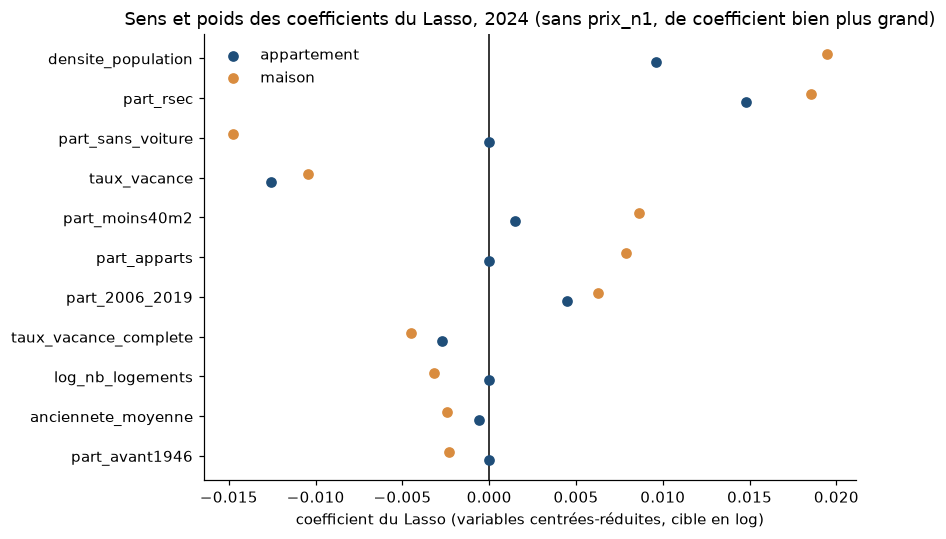

In [28]:
sans_n1 = coef.drop("prix_n1")
ordre = sans_n1["maison"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(ordre))
ax.scatter(sans_n1.loc[ordre, "appartement"], y - 0.1, color=BLEU, label="appartement", zorder=3)
ax.scatter(sans_n1.loc[ordre, "maison"], y + 0.1, color="#d98c3f", label="maison", zorder=3)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, ordre)
ax.set_xlabel("coefficient du Lasso (variables centrées-réduites, cible en log)")
ax.set_title("Sens et poids des coefficients du Lasso, 2024 (sans prix_n1, de coefficient bien plus grand)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 6.4 bis Les sept variables « qui ne comptaient nulle part à l'audit » (étape 1.2)
La feuille de route demande de regarder ce que deviennent, dans le modèle complet, les sept variables dont l'importance SHAP était sous 2 % dans les quatre modèles de l'audit du 31/10 (passage 1 du notebook d'audit) : `part_indicateurs_estimes`, `part_menages_couverts`, `taux3_stupefiants`, `taux3_cambriolages`, `taux3_vols_violents`, `taux_equip_sante`, `taux_vacance_complete`. Le tableau donne le statut de chacune dans ce notebook et son coefficient dans le Lasso 2024 quand elle y est (0 = écartée). *Le passage 2 de l'audit (avec les ménages) en compte huit, avec deux variables de familles à la place des vols violents ; la feuille de route renvoie au passage 1.*

In [29]:
SEPT = ["part_indicateurs_estimes", "part_menages_couverts", "taux3_stupefiants", "taux3_cambriolages",
        "taux3_vols_violents", "taux_equip_sante", "taux_vacance_complete"]
CONTROLE = ["part_indicateurs_estimes", "part_menages_couverts"]

def coef_lasso(nom, variables, type_bien, annee=2024):
    m = ajustes[(nom, annee, type_bien)][0]
    est = m.best_estimator_ if hasattr(m, "best_estimator_") else m
    return pd.Series(est.regressor_.named_steps["modele"].coef_, index=variables)

c_modele = {t: coef_lasso(LASSO, MODELE_COMPLET, t) for t in ["appartement", "maison"]}
c_equip = {t: coef_lasso(LASSO_EQ, AVEC_EQUIPEMENTS, t) for t in ["appartement", "maison"]}
lignes = []
for v in SEPT:
    if v in MODELE_COMPLET:
        statut, src = "dans le modèle complet", c_modele
    elif v in AVEC_EQUIPEMENTS:
        statut, src = "dans la variante + équipements seulement", c_equip
    elif v in CONTROLE:
        statut, src = "hors modèle : contrôle qualité (ne sert pas à prévoir)", None
    else:
        statut, src = "hors modèle : délinquance non retenue (H3b)", None
    lignes.append({"variable": v, "statut": statut,
                   "coef. Lasso appartement": None if src is None else src["appartement"][v],
                   "coef. Lasso maison": None if src is None else src["maison"][v]})
pd.DataFrame(lignes).round(4)

,variable,statut,coef. Lasso appartement,coef. Lasso maison
0,part_indicateurs_estimes,hors modèle : contrôle qualité (ne sert pas à ...,NaN,NaN
1,part_menages_couverts,hors modèle : contrôle qualité (ne sert pas à ...,NaN,NaN
2,taux3_stupefiants,hors modèle : délinquance non retenue (H3b),NaN,NaN
3,taux3_cambriolages,hors modèle : délinquance non retenue (H3b),NaN,NaN
4,taux3_vols_violents,hors modèle : délinquance non retenue (H3b),NaN,NaN
5,taux_equip_sante,dans la variante + équipements seulement,0.0033,0.0031
6,taux_vacance_complete,dans le modèle complet,-0.0027,-0.0045


**Lecture.** Sur les sept variables de l'audit, **deux sont de contrôle qualité** (elles ne servent pas à prévoir) et **trois de délinquance** ne sont pas dans le modèle complet (H3b ne les a pas retenues) : elles restent hors modèle, cohérent avec leur faible importance à l'audit. **`taux_vacance_complete`** est dans le modèle complet et **survit au Lasso** pour les deux types de bien (coefficient négatif, faible : sa contribution moyenne reste sous 1 %, section 6.5) ; elle apporte donc un signal de même sens que `taux_vacance`, pas un gain mesurable à elle seule. **`taux_equip_sante`** n'entre que dans la variante équipements, où le Lasso la garde (coefficient positif faible) sans que la variante n'améliore les résultats (section 5). Ces sept variables confirment le constat de l'audit : peu de poids, et aucune raison de les réintégrer.

### 6.5 Contributions de chaque variable (équivalent SHAP) pour le modèle retenu pour le T1
Modèle étudié : **Elastic Net – modèle complet**, année jugée 2024, par type de bien (choix fixé avant les résultats : le plus simple parmi des régularisées à quelques €/m² les unes des autres ; le Ridge sert de contrôle en 6.6).

Pour un modèle linéaire, la valeur SHAP d'une variable est exactement **coefficient × (valeur centrée-réduite)** : on la calcule sans la bibliothèque `shap`, avec le même résultat. La cible est en log, une contribution de 0,05 se lit « environ +5 % sur le prix ». On donne la contribution absolue moyenne de chaque variable sur l'année jugée (son importance).

In [30]:
MODELE_T1 = ELASTIC          # Elastic Net – modèle complet (choix fixé avant les résultats)
TYPES_T1 = ["appartement", "maison"]

def contributions(nom, annee, type_bien):
    """Contributions linéaires (équivalent SHAP, en log du prix) de chaque variable sur l'année jugée."""
    m, X_ev, _ = ajustes[(nom, annee, type_bien)]
    est = m.best_estimator_.regressor_ if hasattr(m, "best_estimator_") else m.regressor_
    Z = est.named_steps["echelle"].transform(X_ev)            # variables transformées, centrées-réduites
    coef = est.named_steps["modele"].coef_
    contrib = pd.DataFrame(Z * coef, index=X_ev.index, columns=X_ev.columns)
    # Contrôle : intercept + somme des contributions = prévision en log
    assert np.allclose(est.named_steps["modele"].intercept_ + contrib.sum(axis=1), est.predict(X_ev))
    return contrib

tab = {}
for tb in TYPES_T1:
    c = contributions(MODELE_T1, 2024, tb)
    tab[tb] = c.abs().mean() * 100
shap_tab = pd.DataFrame(tab).sort_values("maison", ascending=False).rename_axis("importance : contribution absolue moyenne (%)")
shap_tab.round(2)

,appartement,maison
importance : contribution absolue moyenne (%),,
prix_n1,40.07,35.48
part_rsec,1.80,1.47
densite_population,1.27,1.40
part_sans_voiture,0.00,1.07
taux_vacance,1.31,0.84
part_moins40m2,0.53,0.62
part_apparts,0.00,0.60
part_2006_2019,0.68,0.50
taux_vacance_complete,0.50,0.34


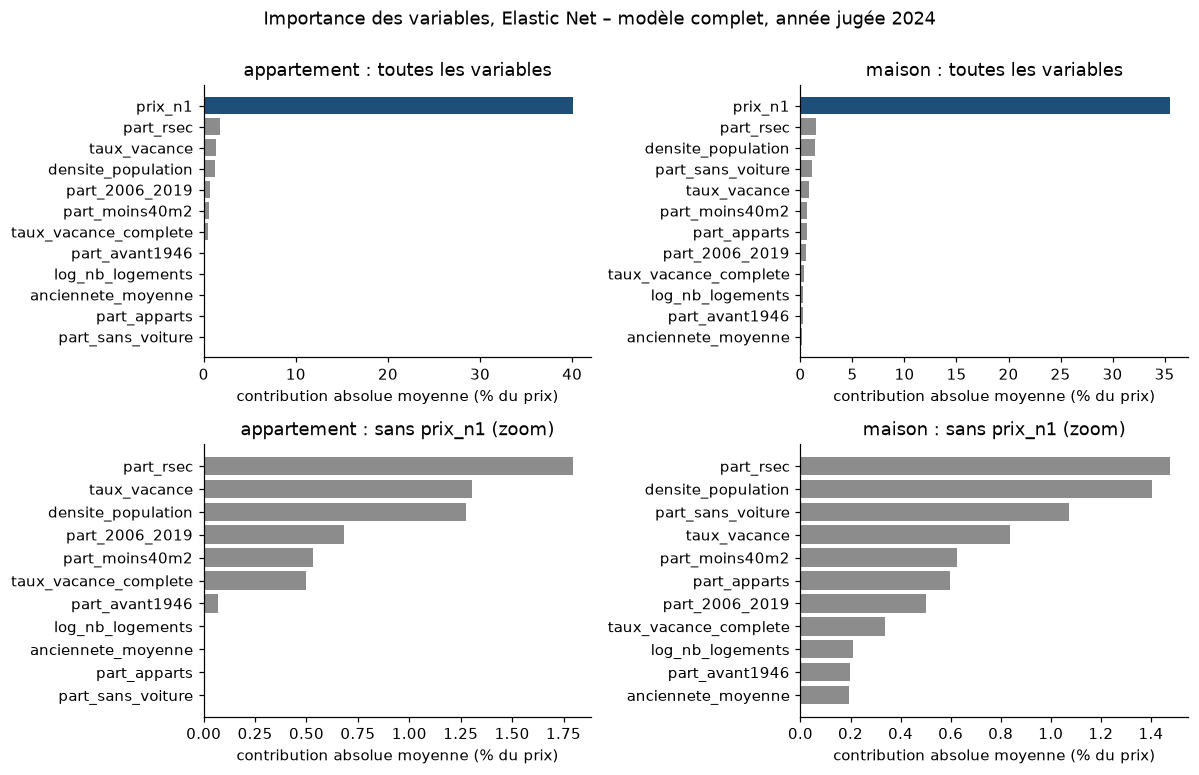

In [31]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLEU, GRIS = "#1f4e79", "#8c8c8c"

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, tb in enumerate(TYPES_T1):
    s = shap_tab[tb].sort_values()
    axes[0, j].barh(s.index, s.values, color=[BLEU if v == s.max() else GRIS for v in s.values])
    axes[0, j].set_title(f"{tb} : toutes les variables")
    s2 = s.drop("prix_n1")
    axes[1, j].barh(s2.index, s2.values, color=GRIS)
    axes[1, j].set_title(f"{tb} : sans prix_n1 (zoom)")
    for k in (0, 1):
        axes[k, j].set_xlabel("contribution absolue moyenne (% du prix)")
fig.suptitle("Importance des variables, Elastic Net – modèle complet, année jugée 2024", y=1.0)
fig.tight_layout()
plt.show()

**Lecture.** `prix_n1` porte presque toute la prévision : sa contribution absolue moyenne est d'environ 40 % pour les appartements et 35 % pour les maisons, contre 2 % au plus pour chaque autre variable (résidences secondaires, densité, vacance en tête ; quatre variables sont mises à zéro pour les appartements : part_sans_voiture, part_apparts, log_nb_logements, anciennete_moyenne). Autrement dit, le modèle prévoit surtout *l'écart de niveau entre les territoires*, déjà contenu dans le prix N-1, et les variables du territoire n'y changent presque rien. Ces contributions décrivent le modèle sur une année et un type de bien, sans test.

### 6.6 Diagnostic T1 : part commune et part propre de l'erreur
**Question :** l'erreur de 2024 vient-elle d'un décalage **commun à tous les territoires** (le « quand » : le marché a changé de phase) ou de l'erreur **propre à chaque territoire** (le « où ») ?

**Calcul**, par type de bien et par année jugée :
- erreur d'un territoire = prévision − prix réel (positive : surestimation) ;
- **part commune** = erreur moyenne de tous les territoires ; **part propre** = erreur du territoire − part commune ;
- on retire la part commune à la prévision et on compare à la naïve avec `evaluer` et `tester`, de deux façons : contre la **naïve telle quelle** (comme demandé par la feuille de route), et contre la **naïve elle aussi privée de sa part commune** (comparaison à égalité : la naïve a aussi une part commune, la lui laisser avantagerait le modèle).

**Limite à retenir :** la part commune utilise l'erreur réelle de l'année jugée. C'est un outil de diagnostic, pas un modèle : on ne peut pas la connaître avant l'année. Le Ridge sert de contrôle, pour vérifier que la lecture ne dépend pas du modèle choisi.

In [32]:
resultats_t1, tests_t1, parts = [], [], []
for nom_modele, etiquette in [(ELASTIC, "Elastic Net"), (RIDGE, "Ridge")]:
    for annee, (app, ev) in FENETRES.items():
        prev = previsions[(nom_modele, annee)]
        type_bien = ev.index.get_level_values("type_bien")
        err = prev - ev[CIBLE]                                              # signée : positive = surestimation
        part_commune = err.groupby(type_bien).transform("mean")             # erreur moyenne de tous les territoires
        prev_sans = prev - part_commune                                     # prévision sans la part commune
        err_naive = ev["prix_n1"] - ev[CIBLE]
        part_commune_naive = err_naive.groupby(type_bien).transform("mean")
        ev_naive_sans = ev.copy()
        ev_naive_sans["prix_n1"] = ev["prix_n1"] - part_commune_naive      # naïve sans sa part commune
        nom1 = f"{HYPOTHESE} – T1 – {etiquette} sans part commune, contre naïve"
        nom2 = f"{HYPOTHESE} – T1 – {etiquette} sans part commune, contre naïve sans part commune"
        evaluer(nom1, ev, prev_sans, resultats_t1); tester(nom1, ev, prev_sans, tests_t1)
        evaluer(nom2, ev_naive_sans, prev_sans, resultats_t1); tester(nom2, ev_naive_sans, prev_sans, tests_t1)
        for tb in TYPES_T1:
            sel = type_bien == tb
            parts.append({"modèle": etiquette, "année jugée": annee, "type de bien": tb,
                          "part commune du modèle (€/m²)": part_commune[sel].iloc[0],
                          "part commune de la naïve (€/m²)": part_commune_naive[sel].iloc[0],
                          "MAE modèle (€/m²)": err[sel].abs().mean(),
                          "MAE modèle sans part commune (€/m²)": (err - part_commune)[sel].abs().mean(),
                          "MAE naïve (€/m²)": err_naive[sel].abs().mean(),
                          "MAE naïve sans part commune (€/m²)": (err_naive - part_commune_naive)[sel].abs().mean()})
parts = pd.DataFrame(parts).set_index(["modèle", "année jugée", "type de bien"])
parts.round(1)

part commune du modèle (€/m²)  \
modèle      année jugée type de bien                                  
Elastic Net 2023        appartement                            86.8   
                        maison                                119.8   
            2024        appartement                           149.5   
                        maison                                173.6   
Ridge       2023        appartement                            83.4   
                        maison                                118.0   
            2024        appartement                           155.3   
                        maison                                173.3   

                                      part commune de la naïve (€/m²)  \
modèle      année jugée type de bien                                    
Elastic Net 2023        appartement                             -64.5   
                        maison                                  -30.0   
            2024        appartement                              40.7   
                        maison                                   71.1   
Ridge       2023        appartement                             -64.5   
                        maison                                  -30.0   
            2024        appartement                              40.7   
                        maison                                   71.1   

                                      MAE modèle (€/m²)  \
modèle      année jugée type de bien                      
Elastic Net 2023        appartement               168.2   
                        maison                    158.0   
            2024        appartement               196.7   
                        maison                    197.2   
Ridge       2023        appartement               170.9   
                        maison                    156.8   
            2024        appartement               202.0   
                        maison                    197.0   

                                      MAE modèle sans part commune (€/m²)  \
modèle      année jugée type de bien                                        
Elastic Net 2023        appartement                                 151.3   
                        maison                                      117.7   
            2024        appartement                                 148.0   
                        maison                                      140.5   
Ridge       2023        appartement                                 157.0   
                        maison                                      118.5   
            2024        appartement                                 156.2   
                        maison                                      141.1   

                                      MAE naïve (€/m²)  \
modèle      année jugée type de bien                     
Elastic Net 2023        appartement              166.3   
                        maison                   111.7   
            2024        appartement              148.0   
                        maison                   129.2   
Ridge       2023        appartement              166.3   
                        maison                   111.7   
            2024        appartement              148.0   
                        maison                   129.2   

                                      MAE naïve sans part commune (€/m²)  
modèle      année jugée type de bien                                      
Elastic Net 2023        appartement                                156.2  
                        maison                                     111.6  
            2024        appartement                                145.1  
                        maison                                     118.2  
Ridge       2023        appartement                                156.2  
                        maison                                     111.6  
            2024        appartement                  

In [33]:
rt, tt = pd.DataFrame(resultats_t1), pd.DataFrame(tests_t1)
cles = ["modèle", "type de bien", "année jugée"]
t1 = rt[cles + ["gain sur la naïve (%)"]].merge(tt[cles + ["IC 95 % bas (€/m²)", "IC 95 % haut (€/m²)", "rang-bisériale"]], on=cles)
t1["comparaison"] = t1["modèle"].str.contains("contre naïve sans part commune").map({True: "naïve sans part commune (égalité)", False: "naïve telle quelle"})
t1["modèle"] = t1["modèle"].str.extract(r"T1 – (Elastic Net|Ridge)")
t1["règle 1.5 remplie"] = (t1["IC 95 % haut (€/m²)"] < 0) & (t1["rang-bisériale"] < 0) & (t1["gain sur la naïve (%)"] >= SEUIL_GAIN)
t1.sort_values(["année jugée", "type de bien", "modèle", "comparaison"]).round(2).reset_index(drop=True)

,modèle,type de bien,année jugée,gain sur la naïve (%),IC 95 % bas (€/m²),IC 95 % haut (€/m²),rang-bisériale,comparaison,règle 1.5 remplie
0,Elastic Net,appartement,2023,3.09,-11.07,0.76,-0.05,naïve sans part commune (égalité),False
1,Elastic Net,appartement,2023,9.01,-22.17,-8.45,-0.18,naïve telle quelle,True
2,Ridge,appartement,2023,-0.57,-4.40,6.12,0.02,naïve sans part commune (égalité),False
3,Ridge,appartement,2023,5.58,-17.98,-1.58,-0.12,naïve telle quelle,True
4,Elastic Net,maison,2023,-5.51,2.51,10.12,0.14,naïve sans part commune (égalité),False
5,Elastic Net,maison,2023,-5.40,2.20,10.13,0.18,naïve telle quelle,False
6,Ridge,maison,2023,-6.16,3.29,10.86,0.15,naïve sans part commune (égalité),False
7,Ridge,maison,2023,-6.05,2.92,10.99,0.18,naïve telle quelle,False
8,Elastic Net,appartement,2024,-2.03,-14.57,14.55,0.11,naïve sans part commune (égalité),False
9,Elastic Net,appartement,2024,-0.03,-18.94,13.29,0.07,naïve telle quelle,False


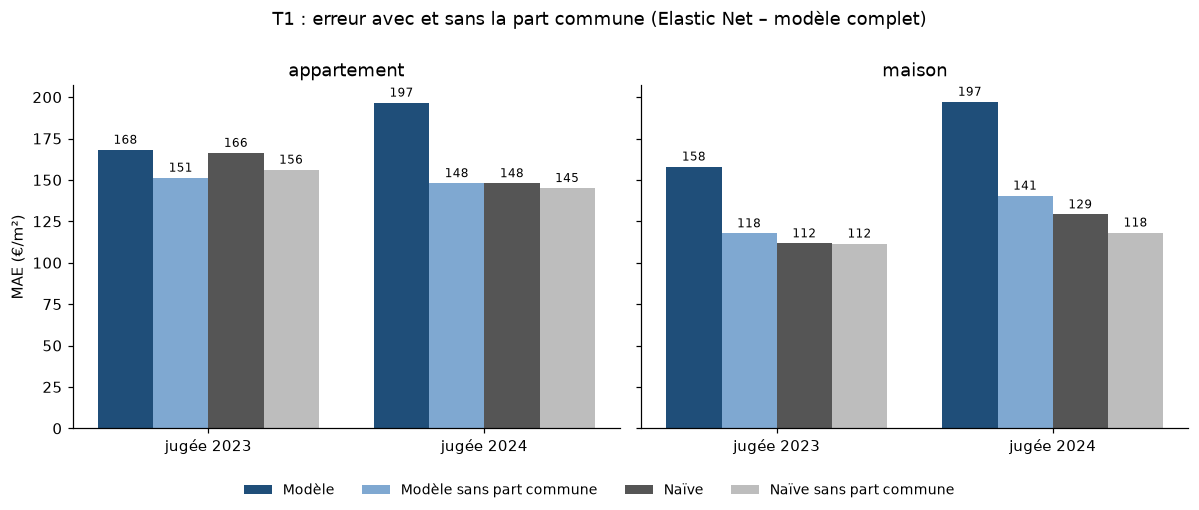

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
p = parts.xs("Elastic Net", level="modèle")
couleurs = {"Modèle": BLEU, "Modèle sans part commune": "#7fa8d1", "Naïve": "#555555", "Naïve sans part commune": "#bdbdbd"}
colonnes = {"Modèle": "MAE modèle (€/m²)", "Modèle sans part commune": "MAE modèle sans part commune (€/m²)",
            "Naïve": "MAE naïve (€/m²)", "Naïve sans part commune": "MAE naïve sans part commune (€/m²)"}
for ax, tb in zip(axes, TYPES_T1):
    sous = p.xs(tb, level="type de bien")
    x = np.arange(len(sous.index))
    for k, (nom, col) in enumerate(colonnes.items()):
        b = ax.bar(x + (k - 1.5) * 0.2, sous[col], width=0.2, label=nom, color=couleurs[nom])
        ax.bar_label(b, fmt="%.0f", fontsize=8, padding=2)
    ax.set_xticks(x, [f"jugée {a}" for a in sous.index])
    ax.set_title(tb)
axes[0].set_ylabel("MAE (€/m²)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="lower center", frameon=False, fontsize=9)
fig.suptitle("T1 : erreur avec et sans la part commune (Elastic Net – modèle complet)", y=1.0)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

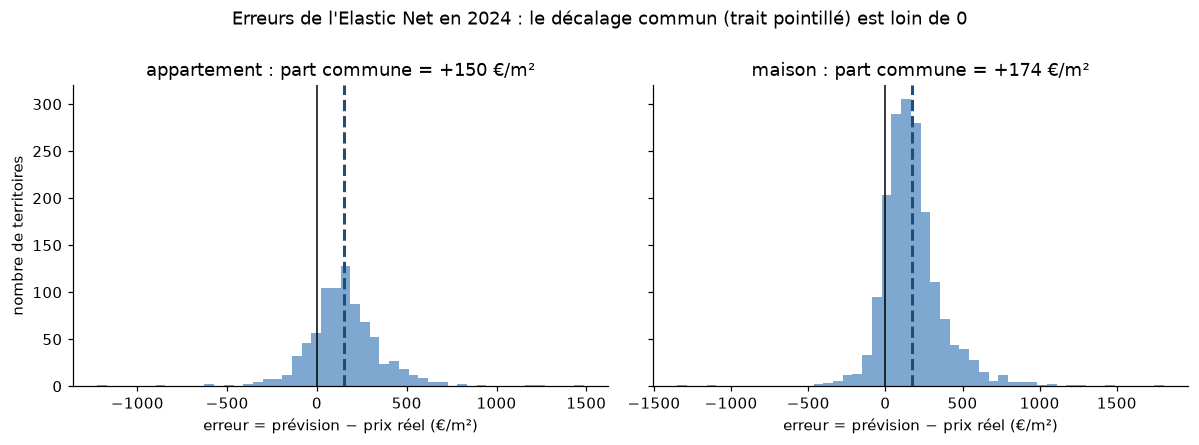

In [35]:
ev24 = FENETRES[2024][1]
err24 = previsions[(ELASTIC, 2024)] - ev24[CIBLE]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, tb in zip(axes, TYPES_T1):
    e = err24[err24.index.get_level_values("type_bien") == tb]
    ax.hist(e, bins=50, color="#7fa8d1")
    ax.axvline(0, color="black", lw=1)
    ax.axvline(e.mean(), color=BLEU, lw=2, ls="--")
    ax.set_title(f"{tb} : part commune = {e.mean():+.0f} €/m²")
    ax.set_xlabel("erreur = prévision − prix réel (€/m²)")
axes[0].set_ylabel("nombre de territoires")
fig.suptitle("Erreurs de l'Elastic Net en 2024 : le décalage commun (trait pointillé) est loin de 0", y=1.0)
fig.tight_layout()
plt.show()

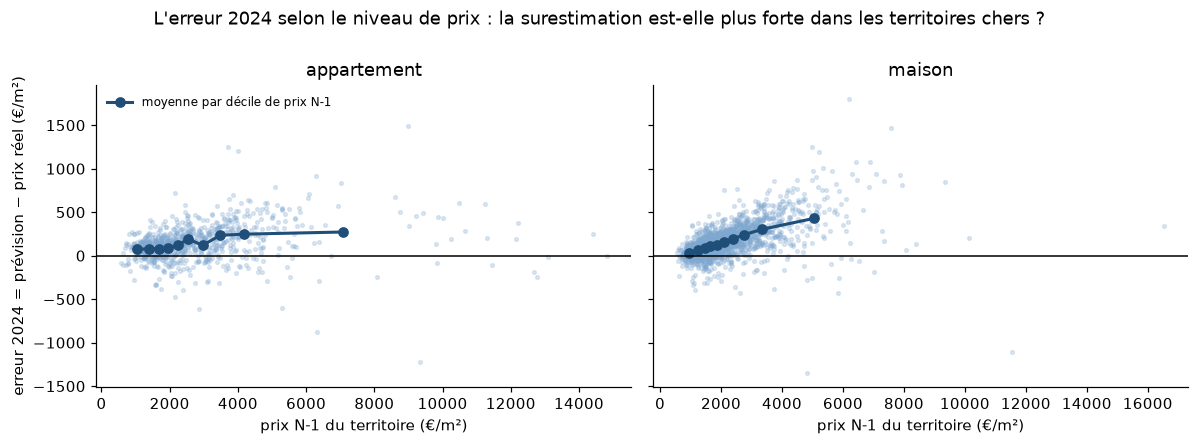

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, tb in zip(axes, TYPES_T1):
    sel = err24.index.get_level_values("type_bien") == tb
    x, y = ev24.loc[sel, "prix_n1"], err24[sel]
    ax.scatter(x, y, s=6, alpha=0.25, color="#7fa8d1")
    niveau = pd.qcut(x, 10, duplicates="drop")
    moy = pd.DataFrame({"x": x, "y": y}).groupby(niveau, observed=True).mean()
    ax.plot(moy["x"], moy["y"], color=BLEU, lw=2, marker="o", label="moyenne par décile de prix N-1")
    ax.axhline(0, color="black", lw=1)
    ax.set_title(tb)
    ax.set_xlabel("prix N-1 du territoire (€/m²)")
axes[0].set_ylabel("erreur 2024 = prévision − prix réel (€/m²)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("L'erreur 2024 selon le niveau de prix : la surestimation est-elle plus forte dans les territoires chers ?", y=1.0)
fig.tight_layout()
plt.show()

**Lecture du T1 (2024, Elastic Net ; le Ridge donne la même lecture).**
- **La part commune pèse un quart de l'erreur.** Le modèle surestime de **+150 €/m²** en moyenne pour les appartements et de **+174 €/m²** pour les maisons ; la naïve, de +41 et +71 €/m². En retirant la part commune, la MAE du modèle passe de 197 à **148 €/m²** (appartements, −25 %) et de 197 à **141 €/m²** (maisons, −29 %).
- **Mais même sans part commune, le modèle ne bat pas la naïve en 2024.** Appartements : 148 €/m² contre 148 pour la naïve (égalité : gain de −0,03 %, IC contenant 0) ; maisons : 141 contre 129 (gain de −8,8 %, IC entièrement au-dessus de 0 : le modèle fait vraiment moins bien). À égalité, en privant aussi la naïve de sa part commune, c'est encore moins favorable (−2,0 % et −18,9 %).
- **2023 est plus nuancé.** Pour les appartements, le modèle sans part commune bat la naïve telle quelle (+9,0 %, IC entièrement sous 0 ; Ridge +5,6 %), mais pas à égalité (+3,1 %, IC contenant 0). Pour les maisons, non (−5,5 %). La règle 1.5 est donc remplie une année sur deux, pour les appartements seulement : pas retenu.
- **Lecture selon la grille de la feuille de route :** « même sans la part commune, il ne bat pas la naïve » → **le « où » n'apporte rien de stable au-delà du prix N-1** ; le niveau 2 est utile et le gain attendu vient du « quand » (phase du marché). Cette lecture est à confirmer collectivement ; elle repose sur deux années jugées, toutes deux pendant le retournement.


## 7. Conclusion
**Questions :** (1.0) modèle commun ou séparé ? Une fois les blocs retenus réunis : (1.2) quel gain reste-t-il au-delà du prix N-1 et quelles variables survivent ? (1.3) l'effet propre du sous-bassin apporte-t-il quelque chose ? (1.4) un arbre, une forêt ou un boosting font-ils mieux ?

**0. Modèle commun ou séparé (1.0) :** séparé (section 4.1 bis). Le commun gagne de 5 à 6 €/m² pour les maisons et perd de 10 €/m² pour les appartements : l'écart est faible et va dans les deux sens. *Choix acté avec l'équipe.*

**1. Contre la naïve : aucun modèle n'est retenu** (0 année réussie sur 2, tous modèles confondus : régularisées, hiérarchique, arbre, forêt, boosting). Gain sur la naïve de −1 % à −83 %. Cause, commune à H3a, H3b et H3c : les modèles apprennent sur 2020-2022 (+5 à +10 % par an) et sont jugés sur 2023 (+1 à +3 %) puis 2024 (−1 à −3 %) ; ils prolongent la hausse et surestiment les prix. L'erreur signée est positive partout (+100 à +340 €/m² selon les groupes de contrôle qualité). Le modèle « prix N-1 seul » perd déjà : le problème ne vient pas des blocs.

**2. Contre « prix N-1 seul » : le modèle complet apporte un gain réel mais modeste (7 à 11 %).**
- Ridge, Lasso, Elastic Net et le hiérarchique sont retenus pour les deux types de bien. Le gradient boosting l'est pour les maisons en 2024 seulement ; l'arbre et la forêt ne le sont pas.
- **Où vient le gain :** pour les maisons, des variables du bloc (le Lasso sur le prix N-1 seul ne gagne rien) ; pour les appartements, en grande partie de la régularisation du prix N-1 (Lasso sur le prix N-1 seul : 6 à 9 %), ce qui confirme la remarque de H3a.
- **Équipements (piste H3a) :** un petit gain de plus pour les maisons (8 à 10 % contre 7 à 8 %), rien pour les appartements.

**3. Variables (1.2).** `prix_n1` domine très largement (sections 6.2 et 6.5 : environ 35 à 40 % de contribution moyenne contre 2 % au plus pour chaque autre variable). Le Lasso garde 8 variables sur 12 pour les appartements et les 12 pour les maisons (section 6.4). Après `prix_n1`, les plus fortes sont la densité, la part de résidences secondaires et la vacance. En 2024, seules `prix_n1` et la part de résidences secondaires aident (importance par permutation) : les autres ont un effet appris pendant la hausse qui dessert le modèle pendant le retournement. Sur les sept variables « sans effet à l'audit » (section 6.4 bis) : deux sont des contrôles qualité et trois de la délinquance, hors modèle ; `taux_vacance_complete` survit au Lasso (coefficient faible) et `taux_equip_sante` n'est gardée que dans la variante équipements.

**4. Hiérarchique (1.3).** L'ICC est de 0 à 0,0008 : l'effet propre du sous-bassin n'apporte rien au-delà du prix N-1 et le modèle se comporte comme la régression simple (même MAE à 1-2 €/m² près). Un modèle (maisons 2023) n'a pas convergé, ce qui est attendu quand la variance de groupe est quasi nulle.

**5. Arbres et boosting (1.4).** Le gradient boosting (évolution du prix) fait mieux que l'arbre et la forêt (niveau du prix) mais moins bien que les régularisées. L'emploi pour les maisons (H3c) n'est pas encore ajouté (section 4.6).

**6. Qualité des données :** l'erreur n'est pas concentrée dans les territoires aux données estimées ou complétées ; rapportée au prix, elle est de 8 à 10 % dans tous les groupes (section 6.3).

**Modèle retenu pour le diagnostic T1 : Elastic Net – modèle complet** (règle fixée avant les résultats : le plus simple parmi des régularisées à 2-4 % les unes des autres ; il est le meilleur ou à égalité sur les deux types de bien et les deux années ; le Ridge sert de contrôle). Appartements 2024 : 197 €/m² contre 148 pour la naïve ; maisons 2024 : 197 contre 129.

**7. Diagnostic T1 (section 6.6).** Le modèle surestime de +150 €/m² (appartements) et +174 €/m² (maisons) en 2024, un décalage commun à tous les territoires qui pèse un quart de l'erreur (MAE 197 → 148 et 141 €/m² sans part commune). Même sans elle, le modèle ne bat pas la naïve en 2024 (appartements : égalité ; maisons : −8,8 %). **Le « où » n'apporte rien de stable au-delà du prix N-1 ; le gain attendu est dans le « quand ».** À lire collectivement avec les autres chiffres.

**Test 2025 (section 8) :** aucun modèle n'étant retenu contre la naïve, le candidat est l'Elastic Net complet (choix fixé avant l'ouverture, à présenter à l'équipe lors de la restitution). Il ne bat pas la naïve en 2025 (−14,7 % appartements, −9,6 % maisons ; IC entièrement au-dessus de 0) : le test ne change pas la conclusion, il la renforce.

**Limites :** deux années jugées, toutes deux pendant le retournement ; plusieurs variantes comparées sur les mêmes années (celle qui ressort a pu en profiter) ; l'importance des variables porte sur une année et un type de bien ; l'emploi n'est pas inclus ; plusieurs `alpha` tombent sur le bord de la grille (maisons : 1e-4 et 1e-5, proche d'une régression non pénalisée).


## 8. Test 2025 (ouvert une seule fois pour le niveau 1)
**Décision prise avant l'ouverture** (ajout de ce notebook, à valider par l'équipe lors de la restitution) : aucun modèle n'est retenu contre la naïve au niveau 1, donc la règle « test pour le modèle retenu » ne désigne personne. Le candidat est le **meilleur modèle du niveau 1 selon la règle fixée en section 6.6 : Elastic Net – modèle complet** (le plus simple parmi les régularisées à égalité), jugé **contre la naïve**.

**Critère de lecture, identique à la règle 1.5 (fixé avant le résultat)** : le modèle réussit 2025 pour un type de bien si l'IC 95 % du bootstrap de l'écart de MAE avec la naïve est entièrement sous 0, si la rang-bisériale est négative et si le gain sur la naïve est d'au moins 3 %. Un seul candidat, une seule ouverture : aucune variante n'est regardée sur 2025.

**Ce que cela change par rapport aux sections précédentes** : le modèle est réajusté sur 2020-2024 (alpha et l1_ratio réglés sur les plis temporels de cette période) et prévoit 2025. Rien n'est réglé sur 2025.

In [37]:
FENETRES_NIVEAU1 = FENETRES
FENETRES = fenetres(table, annees_jugees=[2025])          # apprentissage 2020-2024, évaluation 2025
assert FENETRES[2025][0]["annee"].max() == 2024 and (FENETRES[2025][1]["annee"] == 2025).all()
NOM_2025 = lancer("Elastic Net – modèle complet (test 2025)", ElasticNet(max_iter=50_000), MODELE_COMPLET,
                  log=True, grille=GRILLE_EN)
FENETRES = FENETRES_NIVEAU1                                # on referme : 2025 n'est plus rouvert

res_2025 = pd.DataFrame(resultats); res_2025 = res_2025[res_2025["modèle"] == NOM_2025]
tst_2025 = pd.DataFrame(tests);     tst_2025 = tst_2025[tst_2025["modèle"] == NOM_2025]
display(tst_2025.round(3))
regle_decision(res_2025, tst_2025)

H3 – Elastic Net – modèle complet (test 2025) (12 variables)
type de bien  année jugée  MAE (€/m²)  MAE naïve (€/m²)  gain sur la naïve (%)  bassins où le modèle gagne (%)
 appartement         2025       162.7             141.8                  -14.7                            46.6
      maison         2025       113.4             103.5                   -9.6                            46.0


,modèle,type de bien,année jugée,écart de MAE avec la naïve (€/m²),IC 95 % bas (€/m²),IC 95 % haut (€/m²),p-value Wilcoxon,rang-bisériale,bassins de vie
56,H3 – Elastic Net – modèle complet (test 2025),appartement,2025,20.904,6.380,43.148,0.0,0.156,695
57,H3 – Elastic Net – modèle complet (test 2025),maison,2025,9.964,5.607,15.150,0.0,0.133,1606


années réussies  \
modèle                                        type de bien                    
H3 – Elastic Net – modèle complet (test 2025) appartement                 0   
                                              maison                      0   

                                                            années jugées  \
modèle                                        type de bien                  
H3 – Elastic Net – modèle complet (test 2025) appartement               1   
                                              maison                    1   

                                                            retenu  
modèle                                        type de bien          
H3 – Elastic Net – modèle complet (test 2025) appartement    False  
                                              maison         False

In [38]:
# Lecture du résultat déjà obtenu (aucune nouvelle variante) : sens de l'erreur et marché 2025
ev25 = ev25_df = table[table["annee"] == 2025]
err25 = previsions[(NOM_2025, 2025)] - ev25[CIBLE]
marche = (ev25[CIBLE] / ev25["prix_n1"] - 1) * 100
tb = ev25.index.get_level_values("type_bien")
print(pd.DataFrame({"erreur moyenne (€/m²)": err25.groupby(tb).mean(),
                    "part de sous-estimation (%)": (err25 < 0).groupby(tb).mean() * 100,
                    "évolution médiane du prix 2025 (%)": marche.groupby(tb).median(),
                    "évolution moyenne du prix 2025 (%)": marche.groupby(tb).mean()}).round(1))

             erreur moyenne (€/m²)  part de sous-estimation (%)  \
type_bien                                                         
appartement                   41.0                         35.7   
maison                        36.9                         36.3   

             évolution médiane du prix 2025 (%)  \
type_bien                                         
appartement                                 1.5   
maison                                      0.9   

             évolution moyenne du prix 2025 (%)  
type_bien                                        
appartement                                 1.9  
maison                                      1.5  


**Lecture du test 2025.** Le candidat **ne bat pas la naïve** : MAE de 163 contre 142 €/m² pour les appartements (−14,7 %) et de 113 contre 104 €/m² pour les maisons (−9,6 %). Les IC 95 % de l'écart sont entièrement au-dessus de 0 (de +6 à +43 et de +6 à +15 €/m²) : le modèle fait vraiment moins bien, pas seulement un peu moins bien. Il gagne dans 46 % des bassins seulement. Aucun type de bien ne remplit la règle 1.5 (0 année réussie sur 1).

- **Le marché a changé de phase, et l'erreur aussi.** Le prix évolue de +1 à +2 % en 2025 (après −1 à −3 % en 2024). Le modèle surestime encore, mais bien moins qu'en 2024 : +41 €/m² (appartements) et +37 €/m² (maisons) en moyenne, contre +150 et +174. Le biais moyen (+41 €/m²) vaut environ un quart de la MAE appartements (163 €/m²) et un tiers de celle des maisons (113 €/m²) : l'essentiel de l'erreur est propre à chaque territoire, pas un décalage commun.
- **Conséquence pour la question du niveau 1.** Sur trois années (2023, 2024, 2025), dont deux phases de marché différentes, le « où » (variables territoriales) n'apporte rien de stable au-delà du prix N-1 pour battre la naïve. Les variables territoriales gardent un intérêt contre « prix N-1 seul » (sections 5.2 et 6.4), mais pas contre la naïve. C'est l'argument pour ouvrir le niveau 2 (modèle pont, le « quand »).
- **Ce que le test ne dit pas** : il ne départage pas les autres modèles du niveau 1 (un seul candidat a été ouvert, volontairement), et une seule année est jugée.